## Read the data

In [1]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

# 1. Read data (Now it is the same data)

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/groups_retrain_single_allele_balanced_data/" #!CHANGE
APPROACH = "DECOY_PATHS"

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")
ALLELES = ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
          ]
ALLELES = [
    'HLA-A*01:01',
    'HLA-A*03:01',
    # 'HLA-A*02:01б'
   'HLA-DRB1*01:01',
    'HLA-DPA1*01:03-DPB1*04:01'
          ]
selected_alleles = ALLELES
ALLELES

['HLA-A*01:01', 'HLA-A*03:01', 'HLA-DRB1*01:01', 'HLA-DPA1*01:03-DPB1*04:01']

## 2.0 Merge alleles together

In [4]:
# combination_size = len(ALLELES)
ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'])
# ALLELES = sorted([ 'HLA-A*03:01'])
ALLELES = sorted(['HLA-DRB1*01:01'])
ALLELES = sorted(['HLA-DPA1*01:03-DPB1*04:01'])

ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DPA1*01:03-DPB1*04:01'])


combination_size = 2
TOTAL_SPLITS = 1
TARGET_LENGTHS= [13, 14, 15, 16, 17, 18]
# TARGET_LENGTHS= [8, 9, 10, 11, 12]
RUNS = 5
USE_WEIGHTS = True

# SELECTED_RUN = 0
# SELECTED_RUN = {0,1,2,3,4,5, 6, 7, 8, 9}
SELECTED_RUN = {0,1}

# SELECTED_RUN = {0}
#
SELECTED_SPLIT = 0
models_to_read = ['bw']

In [5]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DPA1*01:03-DPB1*04:01+HLA-DRB1*01:01
Length 9: HLA-DPA1*01:03-DPB1*04:01 - 14 HLA-DRB1*01:01 - 113 
Length 10: HLA-DPA1*01:03-DPB1*04:01 - 68 HLA-DRB1*01:01 - 123 
Length 11: HLA-DPA1*01:03-DPB1*04:01 - 288 HLA-DRB1*01:01 - 175 
Length 12: HLA-DPA1*01:03-DPB1*04:01 - 725 HLA-DRB1*01:01 - 368 
Length 13: HLA-DPA1*01:03-DPB1*04:01 - 1366 HLA-DRB1*01:01 - 826 
Length 14: HLA-DPA1*01:03-DPB1*04:01 - 1802 HLA-DRB1*01:01 - 1184 
Length 15: HLA-DPA1*01:03-DPB1*04:01 - 2260 HLA-DRB1*01:01 - 6886 
Length 16: HLA-DPA1*01:03-DPB1*04:01 - 1580 HLA-DRB1*01:01 - 1413 
Length 17: HLA-DPA1*01:03-DPB1*04:01 - 1160 HLA-DRB1*01:01 - 984 
Length 18: HLA-DPA1*01:03-DPB1*04:01 - 756 HLA-DRB1*01:01 - 708 
Length 19: HLA-DPA1*01:03-DPB1*04:01 - 460 HLA-DRB1*01:01 - 316 
Length 20: HLA-DPA1*01:03-DPB1*04:01 - 299 HLA-DRB1*01:01 - 505 
Length 21: HLA-DPA1*01:03-DPB1*04:01 - 165 HLA-DRB1*01:01 - 177 
Length 22: HLA-DPA1*01:03-DPB1*04:01 - 108 HLA-DRB1*01:01 - 80 
Length 23: HLA-DPA1*01:03-DPB1*04:01 - 74 HLA

## Calculate weights for data

In [6]:
TARGET_LENGTHS

[13, 14, 15, 16, 17, 18]

In [7]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [8]:
per_allele_per_kfold_per_length_weights = \
    calculate_weights_based_on_length_counts(count_df_train,
                                             selected_alleles=ALLELES,
                                             total_splits=TOTAL_SPLITS,
                                             selected_lengths=TARGET_LENGTHS,
                                             use_weights=USE_WEIGHTS)

Total data length for split 0 is 20925
Weights for lentgh 13 are {'HLA-DPA1*01:03-DPB1*04:01': 15.318448023426061, 'HLA-DRB1*01:01': 25.332929782082324}
Weights for lentgh 14 are {'HLA-DPA1*01:03-DPB1*04:01': 11.612097669256382, 'HLA-DRB1*01:01': 17.67314189189189}
Weights for lentgh 15 are {'HLA-DPA1*01:03-DPB1*04:01': 9.258849557522124, 'HLA-DRB1*01:01': 3.0387743247168166}
Weights for lentgh 16 are {'HLA-DPA1*01:03-DPB1*04:01': 13.24367088607595, 'HLA-DRB1*01:01': 14.80891719745223}
Weights for lentgh 17 are {'HLA-DPA1*01:03-DPB1*04:01': 18.038793103448278, 'HLA-DRB1*01:01': 21.265243902439025}
Weights for lentgh 18 are {'HLA-DPA1*01:03-DPB1*04:01': 27.678571428571427, 'HLA-DRB1*01:01': 29.555084745762713}


# Read models

In [9]:
MODELS_DESCRIPTIONS = {
    "single_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10],
    },
    "single_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "multiple_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10, 11, 12]
    },
    "single_allele_balanced_class2": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },

        "single_allele_balanced_class2_biger": {
        "path": "experiment_results/alleles_with_groups_and_joiner_states_single_allele_balanced_data/",
        "states": 49,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },
    "multiple_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },

    "multiple_allele_balanced_longer_training": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "100-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },

    "groups_retrain_single_allele_balanced_data": {
        "path": "experiment_results/groups_retrain_single_allele_balanced_data/",
        "states": 45,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [10, 11, 12, 13, 14, 15, 16, 17, 18]},
    "single_allele_with_cycle_base_model": {
        "path": "experiment_results/single_allele_balanced_data_base_model/",
        "states": 25,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01',
                    'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [13, 14, 15, 16, 17, 18],
        "core_start_state": 25,
        "core_end_state": 26

    },
    "multiple_allele_with_cycle_base_model": {
        "path": "experiment_results/single_allele_balanced_data_base_model/",
        "states": 25,
        "params_string": "30-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-DRB1*01:01',
                    'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [13, 14, 15, 16, 17, 18],
        "core_start_state": 25,
        "core_end_state": 26

    },

    "viterbi_big_with_cycle_base_model": {
        "path": "experiment_results/single_allele_balanced_data_base_model/",
        "states": 50,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01',
                    # 'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [13, 14, 15, 16, 17, 18],
        "core_start_state": 50,
        "core_end_state": 51

    }



    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [10]:
MODELS_DESCRIPTIONS.keys()

dict_keys(['single_allele_imbalanced', 'single_allele_balanced', 'multiple_allele_balanced', 'single_allele_balanced_class2', 'single_allele_balanced_class2_biger', 'multiple_allele_imbalanced', 'multiple_allele_balanced_longer_training', 'mix_of_alleles', 'groups_retrain_single_allele_balanced_data', 'single_allele_with_cycle_base_model', 'multiple_allele_with_cycle_base_model', 'viterbi_big_with_cycle_base_model'])

In [12]:
selected_models = [
                 #'single_allele_imbalanced',
                 #'multiple_allele_imbalanced',
                    # 'single_allele_balanced',
                   # 'multiple_allele_balanced',
    # "single_allele_balanced_class2",
    #     "single_allele_with_cycle_base_model",
    # "single_allele_with_cycle_base_model"
     "multiple_allele_with_cycle_base_model"

    # 'multiple_allele_balanced_longer_training'
]


In [13]:
selected_models

['multiple_allele_with_cycle_base_model']

In [14]:
ALLELES

['HLA-DPA1*01:03-DPB1*04:01+HLA-DRB1*01:01']

In [15]:
from hmm_logic_methods import load_model

In [16]:
import itertools

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_binding_model = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()

    model_alleles = set(model_alleles).intersection(set(OLD_ALLELES))
    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)

    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(TOTAL_SPLITS):
                #bw
                if 'bw' in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    print(bw_model_name)
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'bwv' in models_to_read:
                    #bwv
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'v' in models_to_read:
                    #v
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)

0_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
1_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
2_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
3_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
4_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0


In [17]:
model_name

'4_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0'

## First let's try to simplify paths just marking selected states

In [18]:
import logomaker
from collections import defaultdict
def probs_to_info_matrix(distribution):
    amino_acids = list(distribution.parameters[0].keys())
    dummy_df = pd.DataFrame(columns = sorted(amino_acids), index=[0],  dtype=float)
    for i, (acid, prob) in enumerate(distribution.parameters[0].items()):
        dummy_df.loc[0, acid] = prob
    dummy_df.index.name = "pos"
    info_matrix = logomaker.transform_matrix(dummy_df, from_type='probability', to_type='information')
    return info_matrix

per_model_total_df = dict()

for model_key, model in per_name_binding_model.items():
    per_state_information = dict()
    per_state_distribution = dict()
    per_level_information = defaultdict(float)

    for state in model.states:
        if state not in [model.start, model.end]:
            info_matrix = probs_to_info_matrix(state.distribution)
            per_state_distribution[state.name] = state.distribution.parameters[0]
            per_state_information[state.name] = sum(info_matrix.loc[0])
            # per_level_information[name_to_level[state.name]] += per_state_information[state.name]
    info_df = pd.DataFrame(per_state_information.items(), columns=["state", "info"])
    distr_df = pd.DataFrame(per_state_distribution.values())
    total_df = pd.concat([info_df, distr_df], axis=1)
    per_model_total_df[model_key] = total_df

In [19]:
filtered_dfs = list()
per_model_important_states = dict()
if models_to_read == ['bw']:
    for i, (model_key, total_df) in enumerate(per_model_total_df.items()):
        total_df = total_df.sort_values(by='info', ascending=False).copy()
        total_df = total_df[total_df['info'] >= 1]
        total_df['model'] = i
        total_df['model_name'] = model_key
        filtered_dfs.append(total_df)
        per_model_important_states[model_key] = list(total_df['state'].values)

if models_to_read == ['v']:
    per_model_anchors = dict()
    per_name_models = per_name_binding_model
    core_start_state= MODELS_DESCRIPTIONS[selected_models[0]]['core_start_state']
    core_end_state = MODELS_DESCRIPTIONS[selected_models[0]]['core_end_state']
    for i, (model_key, total_df) in enumerate(per_model_total_df.items()):
        total_df = total_df.sort_values(by='info', ascending=False).copy()
        total_df = total_df.loc[[core_start_state,core_end_state]]
        total_df['model'] = i
        total_df['model_name'] = model_key
        filtered_dfs.append(total_df)
        per_model_important_states[model_key] = list(total_df['state'].values)




In [20]:
import numpy as np
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences_mark_core
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])

total_df = pd.DataFrame(index=allele_peptides)
for i, (model_key, model) in enumerate(per_name_binding_model.items()):
    viterbi_paths = get_all_viterbi_paths_for_model_and_sequences_mark_core(model, allele_peptides, per_model_important_states)

    if 'simplified_path' not in total_df.columns:
        total_df['simplified_path'] = viterbi_paths['simplified_path']
    else:
        total_df['simplified_path'] = total_df['simplified_path'].values + viterbi_paths['simplified_path'].values




Model 0_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 20925/20925 [00:07<00:00, 2812.27it/s]


Model 1_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 20925/20925 [00:07<00:00, 2958.85it/s]


Model 2_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 20925/20925 [00:06<00:00, 3047.07it/s]


Model 3_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 20925/20925 [00:06<00:00, 3025.55it/s]


Model 4_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 20925/20925 [00:07<00:00, 2836.65it/s]


In [21]:
total_df['core_start'] = total_df['simplified_path'].apply(lambda x: np.where(np.array(x) > 0)[0]).apply(lambda x: x[0] if len(x) > 0 else 0)

total_df['core_end'] = total_df['simplified_path'].apply(lambda x: np.where(np.array(x) > 0)[0]).apply(lambda x: x[-1] if len(x)> 0 else 1)
total_df['core_len'] = total_df['core_end'] - total_df['core_start'] + 1
total_df['peptide_len'] = total_df.index.str.len()
total_df['core_peptide'] =total_df.apply(lambda row: row.name[row['core_start']:row['core_end'] + 1], axis=1)
total_df = total_df[~total_df.index.duplicated(keep='first')]
total_df['simplified_path'] = total_df['simplified_path'].apply(lambda x: np.round(x.astype(float),2))
total_df['core_path'] = total_df.apply(lambda row: row['simplified_path'][row['core_start']:row['core_end'] + 1] , axis=1)


In [22]:
total_df

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path
KTEYISTEFNRYG,"[0.0, 0.0, 0.0, 5.87, 0.0, 0.0, 3.54, 0.0, 5.8...",3,8,6,13,YISTEF,"[5.87, 0.0, 0.0, 3.54, 0.0, 5.87]"
SIAAVEMEHFLPL,"[0.0, 0.0, 0.0, 0.0, 6.25, 0.0, 0.0, 5.05, 0.0...",4,9,6,13,VEMEHF,"[6.25, 0.0, 0.0, 5.05, 0.0, 6.25]"
KNGFKTQHFVSAK,"[0.0, 0.0, 0.0, 6.08, 0.0, 0.0, 2.4, 0.0, 6.08...",3,8,6,13,FKTQHF,"[6.08, 0.0, 0.0, 2.4, 0.0, 6.08]"
GSSFVGQLFNQHP,"[0.0, 0.0, 0.0, 6.09, 0.0, 0.0, 2.47, 0.0, 6.0...",3,8,6,13,FVGQLF,"[6.09, 0.0, 0.0, 2.47, 0.0, 6.09]"
IMNSFVNDIFERI,"[0.0, 0.0, 0.0, 0.0, 6.13, 0.0, 0.0, 2.51, 0.0...",4,9,6,13,FVNDIF,"[6.13, 0.0, 0.0, 2.51, 0.0, 6.13]"
...,...,...,...,...,...,...,...
GLAKAKPEASFQVWNKDS,"[0.0, 0.0, 0.0, 0.0, 5.12, 0.0, 0.0, 5.09, 0.0...",4,12,9,18,AKPEASFQV,"[5.12, 0.0, 0.0, 5.09, 0.0, 5.12, 2.63, 0.0, 2..."
LPLTVTSQQGVKVKFPPN,"[0.0, 0.0, 0.0, 0.0, 6.1, 0.0, 0.0, 2.48, 0.0,...",4,12,9,18,VTSQQGVKV,"[6.1, 0.0, 0.0, 2.48, 0.0, 6.1, 0.0, 0.0, 1.2]"
GPKPVVFLQHGLLADSSN,"[0.0, 0.0, 0.0, 0.0, 3.9, 2.59, 0.0, 1.31, 1.3...",4,12,9,18,VVFLQHGLL,"[3.9, 2.59, 0.0, 1.31, 1.31, 0.0, 6.49, 0.0, 1..."
TGGKYIGERSVRVWGHRF,"[0.0, 0.0, 0.0, 0.0, 5.92, 0.0, 0.0, 4.72, 0.0...",4,12,9,18,YIGERSVRV,"[5.92, 0.0, 0.0, 4.72, 0.0, 5.92, 0.0, 0.0, 2.3]"


In [23]:
total_df.core_len.value_counts()

9     8793
6     4449
8     2274
10    2221
7     1784
11     469
12     132
5       90
13      29
14       4
4        3
15       1
Name: core_len, dtype: int64

## Show motifs for cores of different lengths

In [24]:
import seaborn as sns
sns.set_theme(style="white")
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

In [35]:
df = total_df
target_core_len = 7
df = df[df['core_len'] == target_core_len]
peptides = df.index.values
core_starts = df['core_start'].values
core_ends = df['core_end'].values
cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]


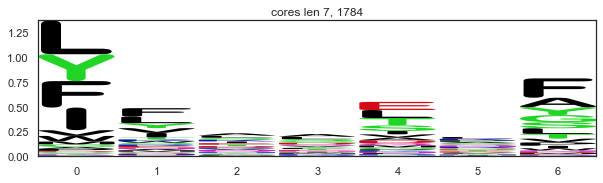

In [36]:
make_logo_for_data(cores, f"cores len {target_core_len}")

In [62]:
df

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path
KTEYISTEFNRYG,"[0.0, 0.0, 0.0, 6.03, 0.0, 0.0, 6.03, 0.0, 6.0...",3,9,7,13,YISTEFN,"[6.03, 0.0, 0.0, 6.03, 0.0, 6.03, 1.26]"
SIAAVEMEHFLPL,"[0.0, 0.0, 0.0, 0.0, 6.11, 0.0, 0.0, 6.11, 0.0...",4,10,7,13,VEMEHFL,"[6.11, 0.0, 0.0, 6.11, 0.0, 6.11, 2.49]"
KNGFKTQHFVSAK,"[0.0, 0.0, 0.0, 6.05, 0.0, 0.0, 6.05, 0.0, 6.0...",3,9,7,13,FKTQHFV,"[6.05, 0.0, 0.0, 6.05, 0.0, 6.05, 2.51]"
GSSFVGQLFNQHP,"[0.0, 0.0, 0.0, 6.08, 0.0, 0.0, 6.08, 0.0, 6.0...",3,9,7,13,FVGQLFN,"[6.08, 0.0, 0.0, 6.08, 0.0, 6.08, 1.23]"
IMNSFVNDIFERI,"[0.0, 0.0, 0.0, 0.0, 6.08, 0.0, 0.0, 4.87, 0.0...",4,10,7,13,FVNDIFE,"[6.08, 0.0, 0.0, 4.87, 0.0, 6.08, 1.21]"
...,...,...,...,...,...,...,...
DGDKGTQRIWAALFLGLG,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 6.33,...",8,14,7,18,IWAALFL,"[6.33, 0.0, 0.0, 3.76, 0.0, 6.33, 2.53]"
YDTLGADDLEGEAFLPLR,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 6.07,...",8,14,7,18,LEGEAFL,"[6.07, 0.0, 0.0, 6.07, 0.0, 6.07, 2.42]"
RQSFGGSLFAYSPGGAHG,"[0.0, 0.0, 0.0, 5.98, 0.0, 0.0, 5.98, 0.0, 5.9...",3,9,7,18,FGGSLFA,"[5.98, 0.0, 0.0, 5.98, 0.0, 5.98, 2.33]"
NPTKNREKIVEVMFETYQ,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 6.3, ...",8,14,7,18,IVEVMFE,"[6.3, 0.0, 0.0, 6.3, 0.0, 6.3, 1.33]"


In [63]:
path  = [item[1].name for item in model.viterbi('SIAAVEMEHFLPL')[1]]
path

['grouped_model-start',
 's027',
 's025',
 's004',
 's000',
 's009',
 's005',
 's012',
 's014',
 's018',
 's019',
 's023',
 's022',
 's026',
 'grouped_model-end']

In [64]:
[per_state_information[state] for state in path[1:-1]]

[0.36540484954190283,
 0.36713462311813116,
 0.410955056632199,
 0.44716432712957077,
 1.4602862002265025,
 0.3495288260709405,
 0.43786180751623294,
 1.3704593964157348,
 0.3207514012609297,
 2.187440698490564,
 1.0211248269275706,
 0.35339436171769767,
 0.7861135884453583]

## Parse Gibbs result

In [37]:
GIBBS_RESULT_PATH = 'gibbs_result/mhcII_1682382/res/gibbs.1g.ds.out'

In [38]:
gibbs_result = pd.read_csv(GIBBS_RESULT_PATH, delimiter=r"\s+")
gibbs_result.index = gibbs_result['Sequence']
gibbs_result = gibbs_result[['Core']].rename(columns={"Core": "Gibbs_core"})

In [39]:
filtered = total_df[total_df['peptide_len'] == 15]
filtered = filtered.join(gibbs_result)

In [55]:
filtered

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,Gibbs_core
DEVLIEVNPPFGDSY,"[0.0, 0.0, 0.0, 6.62, 0.0, 0.0, 6.62, 0.0, 6.6...",3,11,9,15,LIEVNPPFG,"[6.62, 0.0, 0.0, 6.62, 0.0, 6.62, 0.0, 1.36, 3...",NaN
KLATSVLAGLLGVVS,"[0.0, 0.0, 0.0, 5.35, 0.0, 0.0, 6.71, 0.0, 5.3...",3,12,10,15,TSVLAGLLGV,"[5.35, 0.0, 0.0, 6.71, 0.0, 5.35, 1.36, 1.34, ...",NaN
APHYYEQTRGGQVSV,"[0.0, 0.0, 0.0, 1.23, 6.36, 0.0, 0.0, 6.36, 0....",3,12,10,15,YYEQTRGGQV,"[1.23, 6.36, 0.0, 0.0, 6.36, 0.0, 6.36, 0.0, 0...",YEQTRGGQV
VKPLYIITPTNVSHI,"[0.0, 0.0, 0.0, 3.89, 2.74, 0.0, 3.89, 1.36, 5...",3,11,9,15,LYIITPTNV,"[3.89, 2.74, 0.0, 3.89, 1.36, 5.27, 1.36, 0.0,...",LYIITPTNV
KLPLGINITNFRAIL,"[0.0, 0.0, 0.0, 1.43, 3.79, 0.0, 1.43, 3.79, 1...",3,12,10,15,LGINITNFRA,"[1.43, 3.79, 0.0, 1.43, 3.79, 1.43, 5.16, 0.0,...",NaN
...,...,...,...,...,...,...,...,...
QDRQGKTPLTLVDLC,"[0.0, 0.0, 1.38, 0.0, 1.45, 4.08, 1.45, 4.03, ...",2,10,9,15,RQGKTPLTL,"[1.38, 0.0, 1.45, 4.08, 1.45, 4.03, 1.39, 0.0,...",NaN
VNHFVPEAGSRLDQR,"[0.0, 0.0, 0.0, 6.35, 0.0, 0.0, 6.35, 0.0, 6.3...",3,11,9,15,FVPEAGSRL,"[6.35, 0.0, 0.0, 6.35, 0.0, 6.35, 1.34, 0.0, 5...",FVPEAGSRL
WSLTDSSGKDTPGGY,"[0.0, 0.0, 6.37, 0.0, 0.0, 6.37, 0.0, 6.37, 0....",2,10,9,15,LTDSSGKDT,"[6.37, 0.0, 0.0, 6.37, 0.0, 6.37, 0.0, 0.0, 5.05]",LTDSSGKDT
CDLFKKHDDAIVRLR,"[0.0, 0.0, 0.0, 6.74, 0.0, 0.0, 6.74, 0.0, 6.7...",3,11,9,15,FKKHDDAIV,"[6.74, 0.0, 0.0, 6.74, 0.0, 6.74, 1.3, 1.37, 3...",NaN


In [56]:
len(filtered[filtered.Gibbs_core.notnull()])

3670

In [57]:
df_same_cores = filtered[filtered['core_peptide'] == filtered['Gibbs_core']]
len(df_same_cores)

1424

In [58]:
df_our_contains_gibbs =  filtered[filtered.apply(lambda row: str(row['Gibbs_core']) in row['core_peptide']  , axis=1)]
df_our_contains_gibbs = df_our_contains_gibbs.loc[df_our_contains_gibbs.index.difference(df_same_cores.index)]
len(df_our_contains_gibbs)

470

In [59]:
df_our_contains_gibbs

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,Gibbs_core
AAAFQRLHSLQVLVL,"[0.0, 0.0, 0.0, 6.21, 0.0, 0.0, 6.21, 0.0, 6.2...",3,12,10,15,FQRLHSLQVL,"[6.21, 0.0, 0.0, 6.21, 0.0, 6.21, 0.0, 0.0, 3....",FQRLHSLQV
AAFKIAATAANSAPA,"[0.0, 0.0, 2.78, 0.0, 4.05, 2.78, 0.0, 6.83, 0...",2,12,11,15,FKIAATAANSA,"[2.78, 0.0, 4.05, 2.78, 0.0, 6.83, 0.0, 5.45, ...",FKIAATAAN
AAFTSSSKAATAKAP,"[0.0, 0.0, 4.14, 2.7, 0.0, 1.32, 5.52, 1.32, 5...",2,11,10,15,FTSSSKAATA,"[4.14, 2.7, 0.0, 1.32, 5.52, 1.32, 5.44, 0.0, ...",FTSSSKAAT
ACMTKQSDNTMGDVV,"[0.0, 0.0, 6.72, 0.0, 0.0, 6.72, 0.0, 6.72, 1....",2,11,10,15,MTKQSDNTMG,"[6.72, 0.0, 0.0, 6.72, 0.0, 6.72, 1.32, 1.35, ...",MTKQSDNTM
AEAMSQVTNSATIMM,"[0.0, 0.0, 0.0, 6.77, 0.0, 0.0, 6.77, 0.0, 6.7...",3,12,10,15,MSQVTNSATI,"[6.77, 0.0, 0.0, 6.77, 0.0, 6.77, 2.73, 0.0, 4...",MSQVTNSAT
...,...,...,...,...,...,...,...,...
YFVPIFSEAVITSMC,"[0.0, 2.66, 0.0, 2.66, 4.01, 0.0, 5.32, 1.35, ...",1,11,11,15,FVPIFSEAVIT,"[2.66, 0.0, 2.66, 4.01, 0.0, 5.32, 1.35, 4.03,...",FVPIFSEAV
YGTYEKIVGDKVAVW,"[0.0, 0.0, 0.0, 6.23, 0.0, 0.0, 6.23, 0.0, 6.2...",3,12,10,15,YEKIVGDKVA,"[6.23, 0.0, 0.0, 6.23, 0.0, 6.23, 0.0, 0.0, 4....",YEKIVGDKV
YHQVIQQMEQKKLQQ,"[0.0, 0.0, 0.0, 1.37, 4.92, 0.0, 1.37, 4.92, 1...",3,12,10,15,VIQQMEQKKL,"[1.37, 4.92, 0.0, 1.37, 4.92, 1.37, 3.66, 0.0,...",IQQMEQKKL
YNGWDINTPAFEWYY,"[0.0, 0.0, 0.0, 6.63, 0.0, 0.0, 6.63, 0.0, 6.6...",3,12,10,15,WDINTPAFEW,"[6.63, 0.0, 0.0, 6.63, 0.0, 6.63, 2.68, 0.0, 2...",WDINTPAFE


In [60]:
df_our_contains_gibbs.groupby('peptide_len')['core_len'].value_counts()

peptide_len  core_len
15           10          357
             11           69
             12           44
Name: core_len, dtype: int64

In [61]:
df_gibbs_contains_our =  filtered[filtered.apply(lambda row:  row['core_peptide'] in str(row['Gibbs_core']) , axis=1)]
df_gibbs_contains_our = df_gibbs_contains_our.loc[df_gibbs_contains_our.index.difference(df_same_cores.index)]
len(df_gibbs_contains_our)

607

In [62]:
df_gibbs_contains_our

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,Gibbs_core
AAAGAKKAKSPKKAK,"[0.0, 0.0, 0.0, 0.0, 2.72, 1.35, 0.0, 5.31, 1....",4,10,7,15,AKKAKSP,"[2.72, 1.35, 0.0, 5.31, 1.35, 5.31, 1.35]",AKKAKSPKK
AASSYLSLTPEQWKS,"[0.0, 0.0, 0.0, 0.0, 6.44, 0.0, 0.0, 6.44, 0.0...",4,9,6,15,YLSLTP,"[6.44, 0.0, 0.0, 6.44, 0.0, 6.44]",YLSLTPEQW
AATNDHNVMESVTLD,"[0.0, 0.0, 0.0, 0.0, 0.0, 6.79, 0.0, 0.0, 6.79...",5,12,8,15,HNVMESVT,"[6.79, 0.0, 0.0, 6.79, 0.0, 6.79, 0.0, 2.71]",HNVMESVTL
AAYSDQATLLLESPR,"[0.0, 0.0, 6.43, 0.0, 0.0, 6.43, 0.0, 6.43, 0....",2,9,8,15,YSDQATLL,"[6.43, 0.0, 0.0, 6.43, 0.0, 6.43, 0.0, 5.08]",YSDQATLLL
ADAGYAPATPAAAGA,"[0.0, 0.0, 0.0, 0.0, 6.63, 0.0, 0.0, 6.63, 0.0...",4,11,8,15,YAPATPAA,"[6.63, 0.0, 0.0, 6.63, 0.0, 6.63, 0.0, 5.22]",YAPATPAAA
...,...,...,...,...,...,...,...,...
YPFIEQEGPEFFDQE,"[0.0, 0.0, 0.0, 6.43, 0.0, 0.0, 6.43, 0.0, 6.4...",3,10,8,15,IEQEGPEF,"[6.43, 0.0, 0.0, 6.43, 0.0, 6.43, 0.0, 1.32]",FIEQEGPEF
YPSRKEVKILKGLNL,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 6.25, 0.0, 0.0,...",6,11,6,15,VKILKG,"[6.25, 0.0, 0.0, 6.25, 0.0, 6.25]",VKILKGLNL
YPSTQFGSLTGLQSL,"[0.0, 0.0, 0.0, 0.0, 0.0, 6.21, 0.0, 0.0, 6.21...",5,10,6,15,FGSLTG,"[6.21, 0.0, 0.0, 6.21, 0.0, 6.21]",FGSLTGLQS
YTSSDDEIMLSNSHS,"[0.0, 0.0, 0.0, 0.0, 0.0, 6.66, 0.0, 0.0, 6.66...",5,12,8,15,DEIMLSNS,"[6.66, 0.0, 0.0, 6.66, 0.0, 6.66, 0.0, 1.35]",DEIMLSNSH


In [63]:
df_gibbs_contains_our['core_len'].value_counts()

8    457
6    129
7     16
4      3
5      1
2      1
Name: core_len, dtype: int64

In [64]:
gibbs_not_null = filtered[filtered.Gibbs_core.notnull()]

In [65]:
different_cores = gibbs_not_null.loc[gibbs_not_null.index.difference(df_gibbs_contains_our.index).difference(df_same_cores.index).difference(df_our_contains_gibbs.index)]

In [66]:
different_cores['core_len'].value_counts()

9     548
8     269
10    249
11     55
6      27
7      16
12      5
Name: core_len, dtype: int64

In [67]:
gibbs_null = filtered[filtered.Gibbs_core.isnull()]

In [68]:
filtered['core_peptide'].str.startswith(filtered['Gibbs_core'])

DEVLIEVNPPFGDSY   NaN
KLATSVLAGLLGVVS   NaN
APHYYEQTRGGQVSV   NaN
VKPLYIITPTNVSHI   NaN
KLPLGINITNFRAIL   NaN
                   ..
QDRQGKTPLTLVDLC   NaN
VNHFVPEAGSRLDQR   NaN
WSLTDSSGKDTPGGY   NaN
CDLFKKHDDAIVRLR   NaN
KRREGMFIDEKPGNR   NaN
Name: core_peptide, Length: 6694, dtype: float64

In [46]:
gibbs_null[gibbs_null['core_len'] == 9]

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,Gibbs_core


In [47]:
gibbs_null.core_len.value_counts()

12    1563
13    1101
14     333
15      27
Name: core_len, dtype: int64

In [47]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

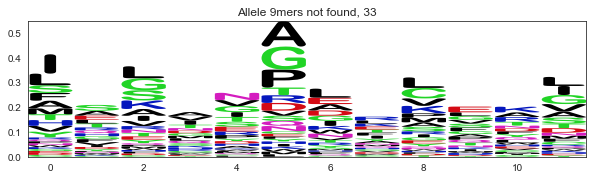

In [443]:
not_found_9 = gibbs_null[gibbs_null['core_len'] == 12]
make_logo_for_data(not_found_9['core_peptide'].values, "9mers not found")

## Cluster cores

In [40]:
total_df

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path
KTEYISTEFNRYG,"[0.0, 0.0, 0.0, 5.87, 0.0, 0.0, 3.54, 0.0, 5.8...",3,8,6,13,YISTEF,"[5.87, 0.0, 0.0, 3.54, 0.0, 5.87]"
SIAAVEMEHFLPL,"[0.0, 0.0, 0.0, 0.0, 6.25, 0.0, 0.0, 5.05, 0.0...",4,9,6,13,VEMEHF,"[6.25, 0.0, 0.0, 5.05, 0.0, 6.25]"
KNGFKTQHFVSAK,"[0.0, 0.0, 0.0, 6.08, 0.0, 0.0, 2.4, 0.0, 6.08...",3,8,6,13,FKTQHF,"[6.08, 0.0, 0.0, 2.4, 0.0, 6.08]"
GSSFVGQLFNQHP,"[0.0, 0.0, 0.0, 6.09, 0.0, 0.0, 2.47, 0.0, 6.0...",3,8,6,13,FVGQLF,"[6.09, 0.0, 0.0, 2.47, 0.0, 6.09]"
IMNSFVNDIFERI,"[0.0, 0.0, 0.0, 0.0, 6.13, 0.0, 0.0, 2.51, 0.0...",4,9,6,13,FVNDIF,"[6.13, 0.0, 0.0, 2.51, 0.0, 6.13]"
...,...,...,...,...,...,...,...
GLAKAKPEASFQVWNKDS,"[0.0, 0.0, 0.0, 0.0, 5.12, 0.0, 0.0, 5.09, 0.0...",4,12,9,18,AKPEASFQV,"[5.12, 0.0, 0.0, 5.09, 0.0, 5.12, 2.63, 0.0, 2..."
LPLTVTSQQGVKVKFPPN,"[0.0, 0.0, 0.0, 0.0, 6.1, 0.0, 0.0, 2.48, 0.0,...",4,12,9,18,VTSQQGVKV,"[6.1, 0.0, 0.0, 2.48, 0.0, 6.1, 0.0, 0.0, 1.2]"
GPKPVVFLQHGLLADSSN,"[0.0, 0.0, 0.0, 0.0, 3.9, 2.59, 0.0, 1.31, 1.3...",4,12,9,18,VVFLQHGLL,"[3.9, 2.59, 0.0, 1.31, 1.31, 0.0, 6.49, 0.0, 1..."
TGGKYIGERSVRVWGHRF,"[0.0, 0.0, 0.0, 0.0, 5.92, 0.0, 0.0, 4.72, 0.0...",4,12,9,18,YIGERSVRV,"[5.92, 0.0, 0.0, 4.72, 0.0, 5.92, 0.0, 0.0, 2.3]"


In [41]:
total_df.core_len.value_counts()

9     8793
6     4449
8     2274
10    2221
7     1784
11     469
12     132
5       90
13      29
14       4
4        3
15       1
Name: core_len, dtype: int64

In [42]:
# total_df['simplified_path_2'] = total_df['simplified_path'].apply(lambda x: (x> 0).astype(int))
target_peptide_len = [15,16, 17,18]
core_len = 9
target_column_to_cluster = 'core_path'

filtered = total_df[total_df['peptide_len'].isin(target_peptide_len)]
filtered = filtered[filtered['core_len'] == core_len]


In [43]:
filtered

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path
RPVLRASSFQPISGN,"[0.0, 0.0, 0.0, 5.98, 0.0, 0.0, 2.41, 0.0, 5.9...",3,11,9,15,LRASSFQPI,"[5.98, 0.0, 0.0, 2.41, 0.0, 5.98, 0.0, 0.0, 2.45]"
DGKVYYTDVFLDVIR,"[0.0, 0.0, 0.0, 0.0, 6.25, 0.0, 0.0, 3.8, 0.0,...",4,12,9,15,YYTDVFLDV,"[6.25, 0.0, 0.0, 3.8, 0.0, 6.25, 0.0, 0.0, 2.48]"
KGHIIVDEFQNTNVK,"[0.0, 0.0, 0.0, 6.26, 0.0, 0.0, 3.79, 0.0, 6.2...",3,11,9,15,IIVDEFQNT,"[6.26, 0.0, 0.0, 3.79, 0.0, 6.26, 0.0, 0.0, 1.25]"
HKPVQASYFETLRQG,"[0.0, 0.0, 0.0, 6.18, 0.0, 0.0, 2.51, 0.0, 6.1...",3,11,9,15,VQASYFETL,"[6.18, 0.0, 0.0, 2.51, 0.0, 6.18, 0.0, 0.0, 1.31]"
QPTPFVSLFFQRLLR,"[0.0, 0.0, 0.0, 0.0, 6.09, 0.0, 0.0, 3.59, 0.0...",4,12,9,15,FVSLFFQRL,"[6.09, 0.0, 0.0, 3.59, 0.0, 6.09, 0.0, 0.0, 2.4]"
...,...,...,...,...,...,...,...
DPDSRGEYSWAVAQGVKQ,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 6.41, 0.0,...",7,15,9,18,YSWAVAQGV,"[6.41, 0.0, 0.0, 2.53, 0.0, 6.41, 0.0, 0.0, 1.23]"
GLAKAKPEASFQVWNKDS,"[0.0, 0.0, 0.0, 0.0, 5.12, 0.0, 0.0, 5.09, 0.0...",4,12,9,18,AKPEASFQV,"[5.12, 0.0, 0.0, 5.09, 0.0, 5.12, 2.63, 0.0, 2..."
LPLTVTSQQGVKVKFPPN,"[0.0, 0.0, 0.0, 0.0, 6.1, 0.0, 0.0, 2.48, 0.0,...",4,12,9,18,VTSQQGVKV,"[6.1, 0.0, 0.0, 2.48, 0.0, 6.1, 0.0, 0.0, 1.2]"
GPKPVVFLQHGLLADSSN,"[0.0, 0.0, 0.0, 0.0, 3.9, 2.59, 0.0, 1.31, 1.3...",4,12,9,18,VVFLQHGLL,"[3.9, 2.59, 0.0, 1.31, 1.31, 0.0, 6.49, 0.0, 1..."


In [44]:
for i in range(core_len):
    filtered[i] = filtered[target_column_to_cluster].map(lambda x :  x[i])

In [45]:
from sklearn.decomposition import PCA

# overwrite for non-linear test
def get_pca(X, n_components=2, whiten=True):
    pca = PCA(n_components=n_components, whiten=whiten)
    X = X
    print(f"Shape {X.shape}")
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca


In [46]:
from sklearn.preprocessing import StandardScaler
values_to_run_clustering_on = filtered[[i for i in range(core_len)]].copy() #+ ['norm_vi_prob']

unique_values_to_run_clustering_on = values_to_run_clustering_on.copy().drop_duplicates() #+ ['norm_vi_prob']
values_to_run_clustering_on = unique_values_to_run_clustering_on
values_to_run_clustering_on.loc[:, [i for i in range(core_len)]] = StandardScaler().fit_transform(values_to_run_clustering_on)
result = filtered.loc[values_to_run_clustering_on.index].copy()

pca = get_pca(values_to_run_clustering_on)


Shape (6771, 9)
Explained variation per principal component: [0.41792236 0.17012156]


In [47]:
values_to_run_clustering_on

,0,1,2,3,4,5,6,7,8
RPVLRASSFQPISGN,0.265954,-0.298929,-0.241288,-0.880014,-0.282815,0.262061,-0.332605,-0.328437,0.593159
DGKVYYTDVFLDVIR,0.455869,-0.298929,-0.241288,0.202863,-0.282815,0.440192,-0.332605,-0.328437,0.629332
KGHIIVDEFQNTNVK,0.462903,-0.298929,-0.241288,0.195073,-0.282815,0.446789,-0.332605,-0.328437,-0.853763
HKPVQASYFETLRQG,0.406632,-0.298929,-0.241288,-0.802109,-0.282815,0.394010,-0.332605,-0.328437,-0.781417
QPTPFVSLFFQRLLR,0.343327,-0.298929,-0.241288,0.039263,-0.282815,0.334633,-0.332605,-0.328437,0.532871
...,...,...,...,...,...,...,...,...,...
DPDSRGEYSWAVAQGVKQ,0.568411,-0.298929,-0.241288,-0.786528,-0.282815,0.545751,-0.332605,-0.328437,-0.877878
GLAKAKPEASFQVWNKDS,-0.338959,-0.298929,-0.241288,1.207836,-0.282815,-0.305319,1.864035,-0.328437,0.665506
LPLTVTSQQGVKVKFPPN,0.350361,-0.298929,-0.241288,-0.825481,-0.282815,0.341230,-0.332605,-0.328437,-0.914051
GPKPVVFLQHGLLADSSN,-1.197091,2.181097,-0.241288,-1.736967,1.354878,-3.683207,5.088001,-0.328437,-0.829647


In [48]:
values_to_run_clustering_on

,0,1,2,3,4,5,6,7,8
RPVLRASSFQPISGN,0.265954,-0.298929,-0.241288,-0.880014,-0.282815,0.262061,-0.332605,-0.328437,0.593159
DGKVYYTDVFLDVIR,0.455869,-0.298929,-0.241288,0.202863,-0.282815,0.440192,-0.332605,-0.328437,0.629332
KGHIIVDEFQNTNVK,0.462903,-0.298929,-0.241288,0.195073,-0.282815,0.446789,-0.332605,-0.328437,-0.853763
HKPVQASYFETLRQG,0.406632,-0.298929,-0.241288,-0.802109,-0.282815,0.394010,-0.332605,-0.328437,-0.781417
QPTPFVSLFFQRLLR,0.343327,-0.298929,-0.241288,0.039263,-0.282815,0.334633,-0.332605,-0.328437,0.532871
...,...,...,...,...,...,...,...,...,...
DPDSRGEYSWAVAQGVKQ,0.568411,-0.298929,-0.241288,-0.786528,-0.282815,0.545751,-0.332605,-0.328437,-0.877878
GLAKAKPEASFQVWNKDS,-0.338959,-0.298929,-0.241288,1.207836,-0.282815,-0.305319,1.864035,-0.328437,0.665506
LPLTVTSQQGVKVKFPPN,0.350361,-0.298929,-0.241288,-0.825481,-0.282815,0.341230,-0.332605,-0.328437,-0.914051
GPKPVVFLQHGLLADSSN,-1.197091,2.181097,-0.241288,-1.736967,1.354878,-3.683207,5.088001,-0.328437,-0.829647


In [49]:
pca_result = pca.transform(values_to_run_clustering_on)

result[['pca0', 'pca1']] = pca_result


In [56]:
from sklearn.cluster import DBSCAN, KMeans

# clustering  = DBSCAN( min_samples=200, eps=1)
clustering = KMeans(n_clusters=10).fit(values_to_run_clustering_on)
clustering_result =clustering.predict(values_to_run_clustering_on)
# for optics
# clustering.fit_predict(values_to_run_clustering_on)
# clustering_result = clustering.labels_

clustering_result

array([2, 0, 7, ..., 7, 1, 0])

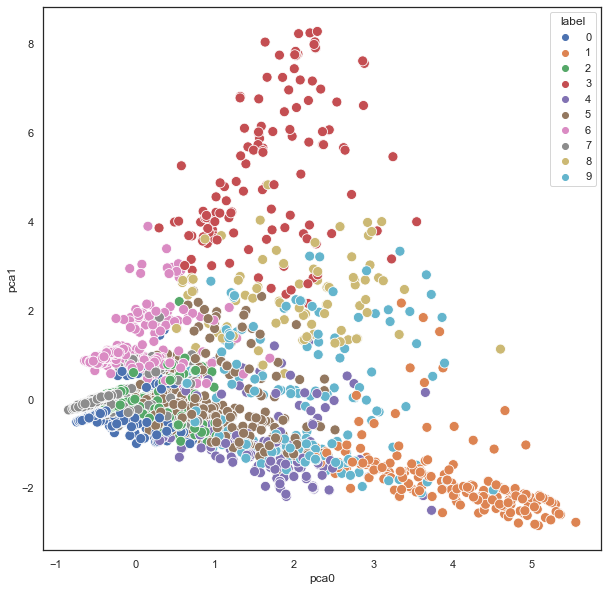

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("white")
fig, ax = plt.subplots(figsize=(10, 10))
result['label'] = clustering_result
graph = sns.scatterplot(data=result, x='pca0', y='pca1', hue='label', s=100,palette='deep', ax=ax)

In [119]:
result.loc[((result['pca0'] > 0) & (result['pca1'] > 0)), 'new_label'] = "1,1"
result.loc[((result['pca0'] > 0) & (result['pca1'] <= 0)), 'new_label'] = "1,-1"
result.loc[((result['pca0'] <= 0) & (result['pca1'] <= 0)), 'new_label'] = "-1,-1"
result.loc[((result['pca0'] <= 0) & (result['pca1'] > 0)), 'new_label'] = "-1,1_0"

#
# result.loc[((result['pca0'] <= 0) & (result['pca1'] > 0.4)), 'new_label'] = "-1,1_1"
# result.loc[((result['pca0'] <= 0) & (result['pca1'] > 0.8)), 'new_label'] = "-1,1_2"
# result.loc[((result['pca0'] <= 0) & (result['pca1'] > 1)), 'new_label'] = "-1,1_3"
# result.loc[((result['pca0'] <= 0) & (result['pca1'] > 1.7)), 'new_label'] = "-1,1_4"
# result.loc[((result['pca0'] <= 0) & (result['pca1'] > 2.3)), 'new_label'] = "-1,1_5"
# result.loc[((result['pca0'] <= 0) & (result['pca1'] <= -0.7)), 'new_label'] = "-1,-1_down"
result.loc[((result['pca0'] > 0) & (result['pca1'] <= -0.7)), 'new_label'] = "1,-1_down"
result.loc[((result['pca0'] > 0.5) & (result['pca1'] <= -0.7)), 'new_label'] = "1,-1_down_0.5"

result.loc[((result['pca0'] > 1) & (result['pca1'] <= 0)), 'new_label'] = "rest"

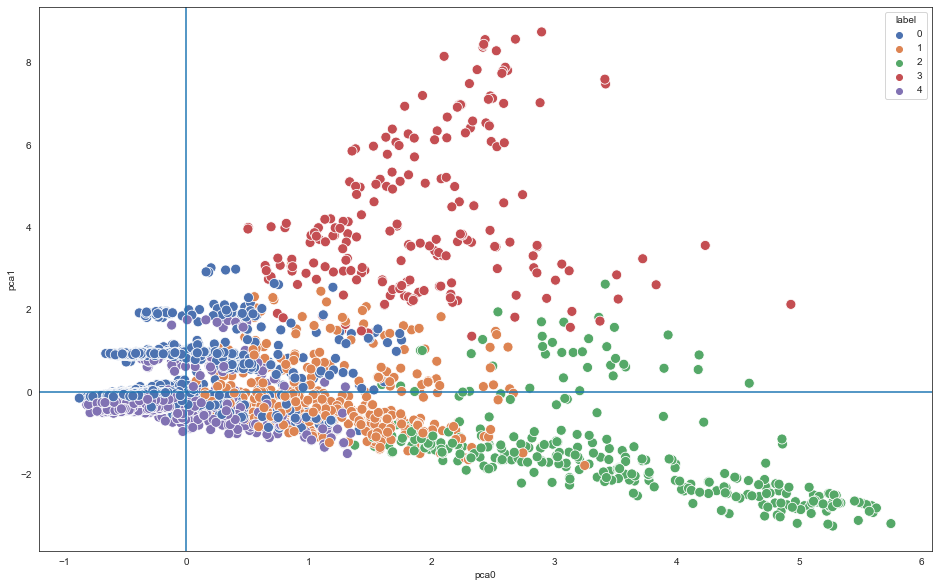

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("white")
fig, ax = plt.subplots(figsize=(16, 10))
result['label'] = clustering_result
graph = sns.scatterplot(data=result, x='pca0', y='pca1', hue='label', s=100,palette='deep', ax=ax)
graph.axhline(0)
graph.axvline(0)

In [58]:
pd.crosstab(result['label'], result['core_len'], values=result.index, aggfunc='count').fillna(0).astype(int)

core_len,9
label,
0,1872
1,188
2,876
3,127
4,162
5,330
6,621
7,2327
8,81


In [59]:
pd.DataFrame(result.groupby(['label', 'core_len'],as_index=False).size())#.pivot(index='size', columns=['label', 'core_len'])

,label,core_len,size
0,0,9,1872
1,1,9,188
2,2,9,876
3,3,9,127
4,4,9,162
5,5,9,330
6,6,9,621
7,7,9,2327
8,8,9,81
9,9,9,187


In [60]:
result.label.value_counts()

7    2327
0    1872
2     876
6     621
5     330
1     188
9     187
4     162
3     127
8      81
Name: label, dtype: int64

In [54]:
result.peptide_len.value_counts()

15    3574
16    1534
17    1018
18     645
Name: peptide_len, dtype: int64

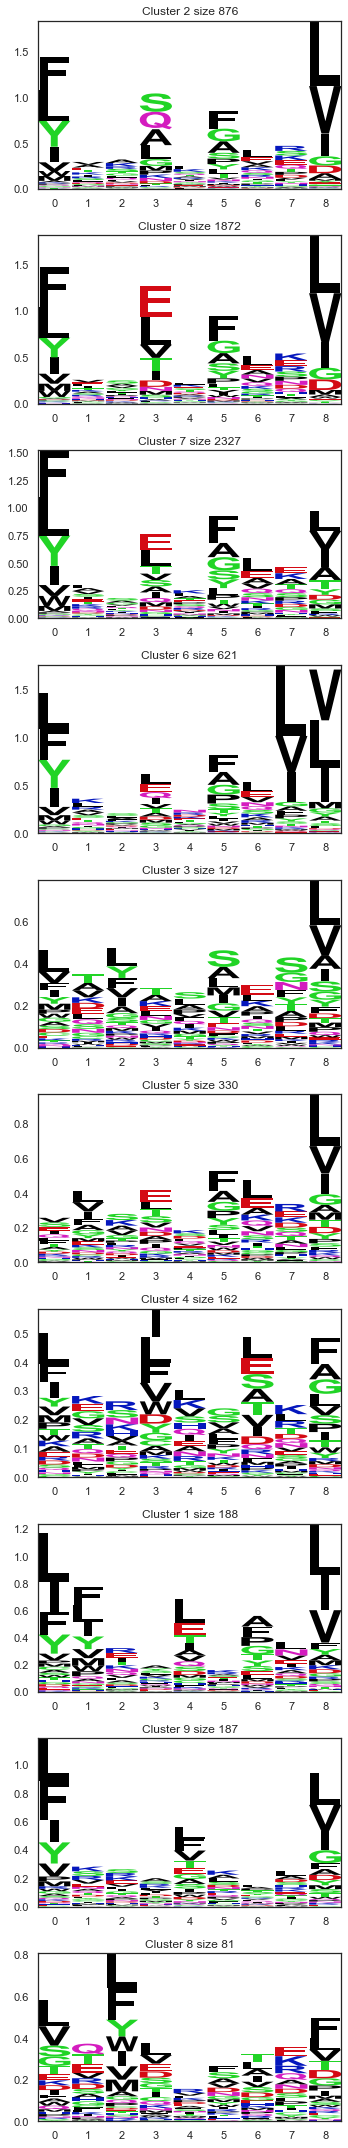

In [61]:
label_to_draw = 'label'

import logomaker
import matplotlib.pyplot as plt
unique_labels = result[label_to_draw].unique()
fig, axes = plt.subplots(nrows=len(unique_labels), ncols=1, figsize=(5, 3*len(unique_labels)))
for i, label in enumerate(unique_labels):
    filtered_for_label = result[result[label_to_draw] == label]
    if len(filtered_for_label) > 0:
        matrix = logomaker.alignment_to_matrix(filtered_for_label['core_peptide'].values)

        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        ww_logo = logomaker.Logo(info_matrix,
                                 # font_name='Arial Rounded MT Bold',
                                 ax=axes[i]
                                 )
        ww_logo.ax.set_title(f"Cluster {label} size {len(filtered_for_label)}")
plt.tight_layout()


In [326]:
result[result.new_label == "-1,-1"]


,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,0,1,2,3,4,5,6,7,8,pca0,pca1,label,new_label
SPSIVIALAGNKADL,"[0.0, 0.0, 0.0, 0.0, 3.82, 0.0, 0.0, 3.82, 0.0...",4,12,9,15,VIALAGNKA,"[3.82, 0.0, 0.0, 3.82, 0.0, 3.82, 0.0, 0.0, 3.05]",3.82,0.0,0.0,3.82,0.0,3.82,0.0,0.00,3.05,-0.739755,-0.457546,4,"-1,-1"
KGNLVELGSFYSDPK,"[0.0, 0.0, 0.0, 3.73, 0.0, 0.0, 3.73, 0.0, 3.7...",3,11,9,15,LVELGSFYS,"[3.73, 0.0, 0.0, 3.73, 0.0, 3.73, 0.0, 0.0, 2.99]",3.73,0.0,0.0,3.73,0.0,3.73,0.0,0.00,2.99,-0.653505,-0.417899,4,"-1,-1"
LLKDVEYARPGLISS,"[0.0, 0.0, 0.0, 0.0, 3.65, 0.0, 0.0, 3.65, 0.0...",4,12,9,15,VEYARPGLI,"[3.65, 0.0, 0.0, 3.65, 0.0, 3.65, 0.0, 0.0, 2.96]",3.65,0.0,0.0,3.65,0.0,3.65,0.0,0.00,2.96,-0.578709,-0.401874,4,"-1,-1"
ADNFLLENTLPAQST,"[0.0, 0.0, 0.0, 3.96, 0.0, 0.0, 3.96, 0.0, 3.9...",3,11,9,15,FLLENTLPA,"[3.96, 0.0, 0.0, 3.96, 0.0, 3.96, 0.0, 0.0, 3.18]",3.96,0.0,0.0,3.96,0.0,3.96,0.0,0.00,3.18,-0.876862,-0.549419,4,"-1,-1"
QKSIVAYTMSLGADS,"[0.0, 0.0, 0.0, 0.0, 3.34, 0.0, 0.0, 3.34, 0.0...",4,12,9,15,VAYTMSLGA,"[3.34, 0.0, 0.0, 3.34, 0.0, 3.34, 0.0, 0.0, 2.64]",3.34,0.0,0.0,3.34,0.0,3.34,0.0,0.00,2.64,-0.272537,-0.171969,4,"-1,-1"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SSFGSGAGSSSFSRTSSS,"[0.0, 0.0, 3.02, 0.0, 0.0, 3.04, 0.0, 3.79, 0....",2,10,9,18,FGSGAGSSS,"[3.02, 0.0, 0.0, 3.04, 0.0, 3.79, 0.0, 0.0, 3.04]",3.02,0.0,0.0,3.04,0.0,3.79,0.0,0.00,3.04,-0.249466,-0.540437,4,"-1,-1"
DGNLRPWWKNSSVEAFKQ,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.8, 0.0, 0.0, ...",6,14,9,18,WWKNSSVEA,"[3.8, 0.0, 0.0, 3.0, 0.0, 3.8, 0.0, 0.0, 3.02]",3.80,0.0,0.0,3.00,0.0,3.80,0.0,0.00,3.02,-0.475445,-0.466787,4,"-1,-1"
RDDGSWEVIEGYRAQHSQ,"[0.0, 0.0, 0.0, 0.0, 0.0, 3.9, 0.0, 0.0, 3.17,...",5,13,9,18,WEVIEGYRA,"[3.9, 0.0, 0.0, 3.17, 0.0, 3.9, 0.0, 0.0, 3.12]",3.90,0.0,0.0,3.17,0.0,3.90,0.0,0.00,3.12,-0.595285,-0.535513,4,"-1,-1"
DVSRFKAIKARFAKPVYP,"[0.0, 0.0, 0.0, 0.0, 4.0, 0.0, 0.0, 4.0, 0.0, ...",4,12,9,18,FKAIKARFA,"[4.0, 0.0, 0.0, 4.0, 0.0, 4.0, 0.0, 0.0, 3.19]",4.00,0.0,0.0,4.00,0.0,4.00,0.0,0.00,3.19,-0.913859,-0.553313,4,"-1,-1"


In [ ]:
target_df  = result[result.label == 2].copy()
target_df['peptide'] = target_df.index.values
target_df['peptide'].to_csv("gibbs_input.csv", index=False, header=False)

In [254]:
target_df

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,0,1,2,3,4,5,6,7,8,pca0,pca1,label,peptide
DSMKALKDALSFHND,"[0.0, 0.0, 3.02, 0.0, 0.0, 3.79, 0.0, 3.79, 0....",2,10,9,15,MKALKDALS,"[3.02, 0.0, 0.0, 3.79, 0.0, 3.79, 0.0, 0.74, 2...",3.02,0.0,0.00,3.79,0.00,3.79,0.0,0.74,2.28,-0.408894,0.485584,2,DSMKALKDALSFHND
KMMNMEAANLAEVRS,"[0.0, 0.0, 2.88, 0.0, 0.71, 2.88, 0.71, 2.88, ...",2,10,9,15,MNMEAANLA,"[2.88, 0.0, 0.71, 2.88, 0.71, 2.88, 0.0, 1.41,...",2.88,0.0,0.71,2.88,0.71,2.88,0.0,1.41,1.47,0.406412,1.460920,2,KMMNMEAANLAEVRS
SEDEIRQTLDYRWVN,"[0.0, 0.0, 0.0, 0.0, 3.58, 0.0, 0.0, 2.9, 0.0,...",4,12,9,15,IRQTLDYRW,"[3.58, 0.0, 0.0, 2.9, 0.0, 3.58, 0.0, 0.0, 0.73]",3.58,0.0,0.00,2.90,0.00,3.58,0.0,0.00,0.73,-0.129294,1.400140,2,SEDEIRQTLDYRWVN
KERQIKKQTALVELV,"[0.0, 0.0, 0.0, 0.0, 3.75, 0.0, 0.0, 3.75, 0.0...",4,12,9,15,IKKQTALVE,"[3.75, 0.0, 0.0, 3.75, 0.0, 3.75, 0.0, 1.56, 0...",3.75,0.0,0.00,3.75,0.00,3.75,0.0,1.56,0.69,-0.469882,2.259168,2,KERQIKKQTALVELV
FPQVGGLTSIKWADN,"[0.0, 0.0, 0.0, 3.74, 0.0, 0.0, 3.74, 0.0, 3.7...",3,11,9,15,VGGLTSIKW,"[3.74, 0.0, 0.0, 3.74, 0.0, 3.74, 0.0, 0.0, 1.53]",3.74,0.0,0.00,3.74,0.00,3.74,0.0,0.00,1.53,-0.545466,0.785639,2,FPQVGGLTSIKWADN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MAKREINKLLKQKEKKNE,"[0.0, 0.0, 0.0, 0.0, 0.0, 3.63, 0.0, 0.0, 3.63...",5,13,9,18,INKLLKQKE,"[3.63, 0.0, 0.0, 3.63, 0.0, 2.84, 0.0, 0.0, 0.68]",3.63,0.0,0.00,3.63,0.00,2.84,0.0,0.00,0.68,-0.143519,1.478982,2,MAKREINKLLKQKEKKNE
YTSGPGSRISSSSFSRVG,"[0.0, 0.0, 0.0, 0.0, 0.0, 2.07, 0.0, 0.0, 2.8,...",5,13,9,18,GSRISSSSF,"[2.07, 0.0, 0.0, 2.8, 0.0, 3.45, 0.0, 1.34, 0.73]",2.07,0.0,0.00,2.80,0.00,3.45,0.0,1.34,0.73,0.412997,1.953667,2,YTSGPGSRISSSSFSRVG
QHDKLVRLYAVVTKEEPI,"[0.0, 0.0, 0.0, 0.0, 3.88, 0.0, 0.0, 3.88, 0.0...",4,12,9,18,LVRLYAVVT,"[3.88, 0.0, 0.0, 3.88, 0.0, 3.88, 0.0, 0.79, 2.3]",3.88,0.0,0.00,3.88,0.00,3.88,0.0,0.79,2.30,-0.725155,0.561979,2,QHDKLVRLYAVVTKEEPI
DQEHIMEHLEGVINKPEA,"[0.0, 0.0, 0.0, 0.0, 0.0, 3.74, 0.0, 0.0, 3.74...",5,13,9,18,MEHLEGVIN,"[3.74, 0.0, 0.0, 3.74, 0.0, 3.74, 0.0, 1.51, 0...",3.74,0.0,0.00,3.74,0.00,3.74,0.0,1.51,0.74,-0.465397,2.191883,2,DQEHIMEHLEGVINKPEA


In [201]:
target_df['core_peptide']

KMMNMEAANLAEVRS       MNMEAANLA
KERQIKKQTALVELV       IKKQTALVE
NPKNFQTMPGTFQTT       FQTMPGTFQ
FGLSYKEQVGSNREL       YKEQVGSNR
EVKSFQWTQALRREL       FQWTQALRR
                        ...    
LHGQFSQAVTPLAHHHTD    FSQAVTPLA
MAKREINKLLKQKEKKNE    INKLLKQKE
YTSGPGSRISSSSFSRVG    GSRISSSSF
DQEHIMEHLEGVINKPEA    MEHLEGVIN
VPNQYNPLRGSVAPGPLS    YNPLRGSVA
Name: core_peptide, Length: 786, dtype: object

In [139]:
input_with_label = result[[i for i in range(9)] + ['label', 'core_peptide']]

In [143]:
pd.DataFrame(input_with_label.groupby('label').sum().loc[2]).T

,0,1,2,3,4,5,6,7,8
2,2913.61,2932.54,2933.28,2952.91,2952.91,2952.91,2716.02,2712.49,2362.99


In [463]:
input_with_label[input_with_label['label'] == 4]

,0,1,2,3,4,5,6,7,8,label,core_peptide
LRNLCELLGVEPPSE,2.10,3.48,3.48,3.48,3.48,3.48,2.08,0.70,0.70,4,LCELLGVEP
NPKNFQTMPGTFQTT,3.65,3.65,3.65,3.65,3.65,3.65,0.73,0.73,0.73,4,FQTMPGTFQ
GPSPKQLVSLGPEKS,2.18,2.18,2.18,3.59,3.59,3.59,1.41,1.41,1.41,4,PKQLVSLGP
FGLSYKEQVGSNREL,3.73,3.73,3.73,3.73,3.73,3.73,0.74,0.74,0.74,4,YKEQVGSNR
EVKSFQWTQALRREL,3.71,3.71,3.71,3.71,3.71,3.71,0.74,0.74,0.74,4,FQWTQALRR
...,...,...,...,...,...,...,...,...,...,...,...
VGHVDEFLSFVPAPDRKG,3.69,3.69,3.69,3.69,3.69,3.69,0.72,0.72,0.72,4,FLSFVPAPD
TYNIADAARHYGVNLNTL,2.98,2.98,2.98,3.72,3.72,3.72,1.50,1.50,1.50,4,YNIADAARH
LTQYFVQENYLEYRQVPG,1.47,3.81,3.81,3.81,3.81,3.81,3.81,0.70,0.70,4,YFVQENYLE
EKGPMFELLPGESNKIPR,3.70,3.70,3.70,3.70,3.70,3.70,1.44,1.44,0.73,4,FELLPGESN


<AxesSubplot:>

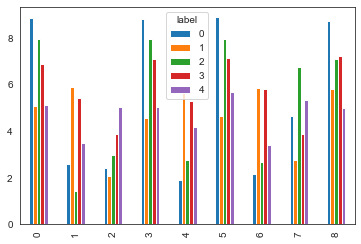

In [108]:
np.log(input_with_label.groupby('label').sum()).T.plot(kind='bar')

In [172]:
input_with_label.groupby('label').sum()

,0,1,2,3,4,5,6,7,8
label,,,,,,,,,
0,6.831630,5.404523,3.909219,7.063955,5.305293,7.090685,5.829093,3.875152,7.190510
1,7.939341,1.423108,2.962175,7.931101,2.775086,7.938199,2.619583,6.738686,7.084151
2,8.840097,2.714032,2.418589,8.827823,1.993339,8.895813,2.227862,4.616802,8.711641
3,5.163471,3.479700,5.041940,5.047032,4.172077,5.690191,3.382354,5.340658,5.011368
4,5.059044,5.885715,2.071913,4.539564,5.917199,4.652245,5.840613,2.693951,5.806429


In [164]:
input_with_label[input_with_label.label == 1].sum(axis=0)

0        2805.51
1           4.15
2          19.34
3        2782.49
4          16.04
5        2802.31
6          13.73
7         844.45
8        1192.91
label     799.00
dtype: float64

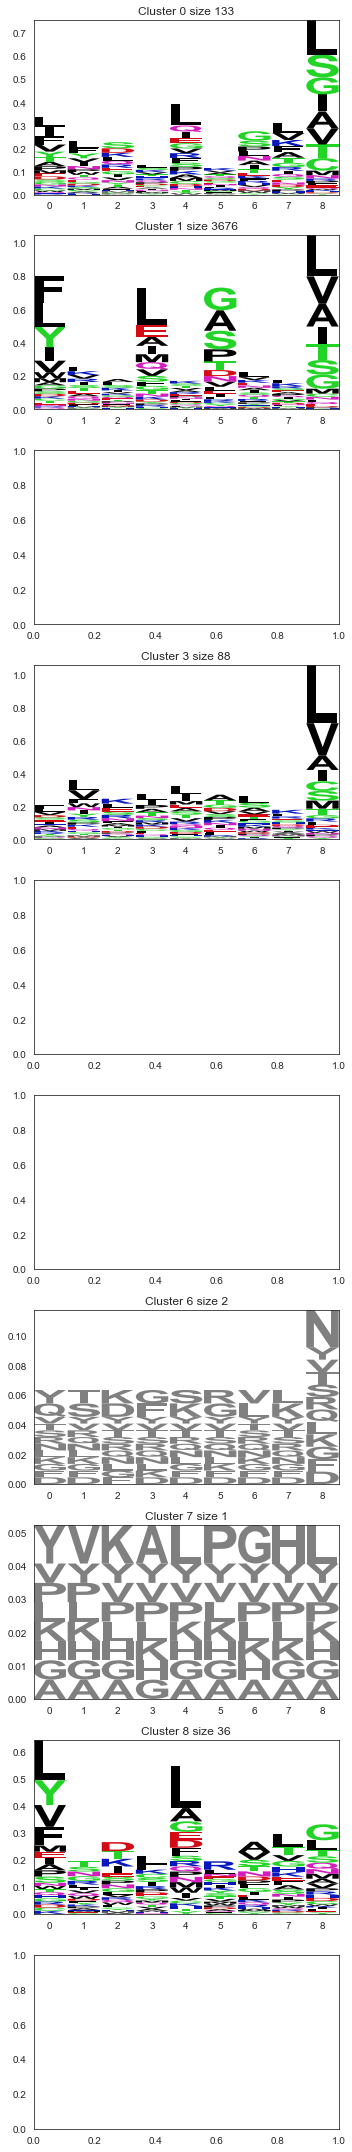

In [731]:
pd.DataFrame(filtered.groupby(['label', 'core_len'],
                              as_index=False).size())  #.pivot(index='size', columns=['label', 'core_len'])
import logomaker
import matplotlib.pyplot as plt

unique_labels = np.unique(clustering.labels_)
fig, axes = plt.subplots(nrows=len(unique_labels), ncols=1, figsize=(5, 3 * len(unique_labels)))
for label in unique_labels:
    filtered_for_label = filtered[filtered['label'] == label]
    if len(filtered_for_label) > 0 :
        peptides = filtered_for_label['core_peptide'].values

        matrix = logomaker.alignment_to_matrix(peptides)

        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        ww_logo = logomaker.Logo(info_matrix,
                                 # font_name='Arial Rounded MT Bold',
                                 ax=axes[label]
                                 )
        ww_logo.ax.set_title(f"Cluster {label} size {len(filtered_for_label)}")
plt.tight_layout()

In [732]:
filtered['core_path'].astype(str).unique()

array(['[3.6 0.  0.  3.6 0.  3.6 0.  0.  3.6]',
       '[3.82 0.   0.   3.82 0.   3.82 0.   0.   3.05]',
       '[3.67 0.   0.   3.67 0.   3.67 0.   0.   3.67]', ...,
       '[3.7  0.   0.   3.7  0.   3.7  0.   0.   0.74]',
       '[3.87 0.   0.   3.87 0.   3.87 0.   0.   3.14]',
       '[2.92 0.   0.   3.67 0.   3.67 0.   0.   3.67]'], dtype=object)

In [733]:
core_length = 9
for i in range(core_length):
    filtered[i] = filtered['core_path'].map(lambda x :x[i])

In [734]:

values_to_run_clustering_on = filtered[[i for i in range(core_length)]] #+ ['norm_vi_prob']
values_to_run_clustering_on = StandardScaler().fit_transform(values_to_run_clustering_on)

pca = get_pca(values_to_run_clustering_on)

Shape (3936, 9)
Explained variation per principal component: [0.51742788 0.2012217 ]


In [735]:
pca_result = pca.transform(values_to_run_clustering_on)
filtered[['pca0', 'pca1']] = pca_result


In [736]:
from sklearn.cluster import KMeans

clustering = KMeans(n_clusters=10).fit(values_to_run_clustering_on)
clustering.labels_

array([5, 5, 5, ..., 5, 9, 5])

<AxesSubplot:xlabel='pca0', ylabel='pca1'>

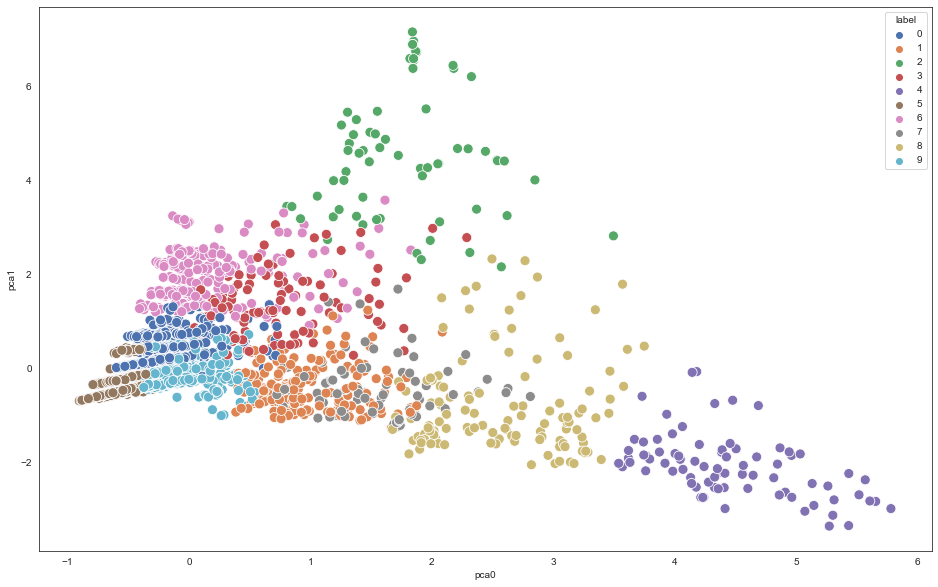

In [739]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("white")
fig, ax = plt.subplots(figsize=(16, 10))
filtered['label'] = clustering.labels_
sns.scatterplot(data=filtered, x='pca0', y='pca1', hue='label', s=100,palette='deep', ax=ax)

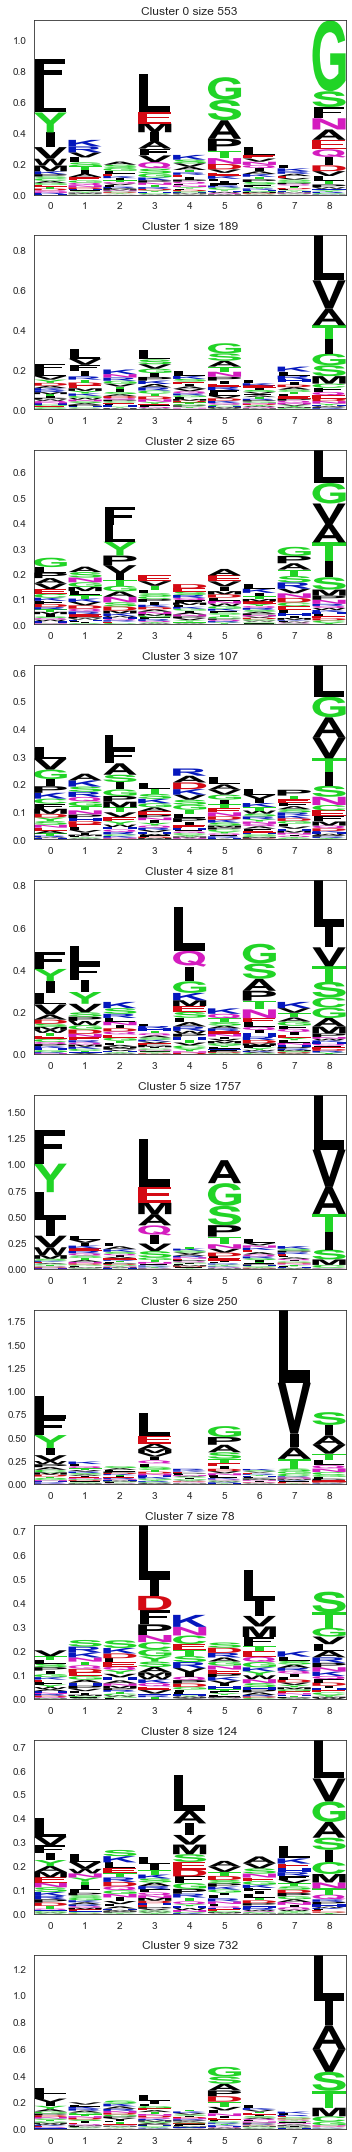

In [740]:
import logomaker
import matplotlib.pyplot as plt
unique_labels = np.unique(clustering.labels_)
fig, axes = plt.subplots(nrows=len(unique_labels), ncols=1, figsize=(5, 3*len(unique_labels)))
for label in unique_labels:
    filtered_for_label = filtered[filtered['label'] == label]

    matrix = logomaker.alignment_to_matrix(filtered_for_label['core_peptide'].values)

    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    ww_logo = logomaker.Logo(info_matrix,
                             # font_name='Arial Rounded MT Bold',
                             ax=axes[label]
                             )
    ww_logo.ax.set_title(f"Cluster {label} size {len(filtered_for_label)}")
plt.tight_layout()

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path
LPWNSLPAKTLSK,"[1.97, 1.97, 3.94, 3.94, 3.94, 4.93, 4.93, 3.9...",0,11,12,13,LPWNSLPAKTLS,"[1.97, 1.97, 3.94, 3.94, 3.94, 4.93, 4.93, 3.9..."
IDPIWSLAANHLS,"[0.0, 2.87, 2.87, 3.86, 3.86, 3.86, 4.85, 4.85...",1,12,12,13,DPIWSLAANHLS,"[2.87, 2.87, 3.86, 3.86, 3.86, 4.85, 4.85, 1.9..."
DSRLVLEVAQHLG,"[0.99, 2.94, 2.94, 3.94, 3.94, 3.94, 4.92, 3.9...",0,12,13,13,DSRLVLEVAQHLG,"[0.99, 2.94, 2.94, 3.94, 3.94, 3.94, 4.92, 3.9..."
FLSFPTTKTYFPH,"[1.91, 4.81, 4.81, 4.81, 4.81, 4.81, 4.81, 2.9...",0,8,9,13,FLSFPTTKT,"[1.91, 4.81, 4.81, 4.81, 4.81, 4.81, 4.81, 2.9..."
AAGYDVEKNNSRI,"[0.97, 2.91, 2.91, 3.9, 3.9, 3.9, 4.86, 3.89, ...",0,12,13,13,AAGYDVEKNNSRI,"[0.97, 2.91, 2.91, 3.9, 3.9, 3.9, 4.86, 3.89, ..."
...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,"[0.0, 0.99, 2.95, 2.95, 3.91, 3.91, 3.91, 4.89...",1,13,13,18,AAVYTLAKTPLIA,"[0.99, 2.95, 2.95, 3.91, 3.91, 3.91, 4.89, 3.9..."
AVPGKTFVSITPAEVGVL,"[0.0, 0.0, 0.0, 1.0, 2.99, 2.99, 3.99, 3.99, 3...",3,15,13,18,GKTFVSITPAEVG,"[1.0, 2.99, 2.99, 3.99, 3.99, 3.99, 4.98, 3.98..."
VPHLRYLRLDGNYLKPPI,"[0.0, 1.95, 2.92, 2.92, 2.92, 3.92, 3.92, 3.92...",1,14,14,18,PHLRYLRLDGNYLK,"[1.95, 2.92, 2.92, 2.92, 3.92, 3.92, 3.92, 4.9..."
DIRRFDPIPAQYVRVYPE,"[0.0, 0.99, 2.95, 2.95, 3.94, 3.94, 3.94, 4.93...",1,13,13,18,IRRFDPIPAQYVR,"[0.99, 2.95, 2.95, 3.94, 3.94, 3.94, 4.93, 3.9..."


In [288]:
total_df.core_len.value_counts()

13    5212
12    2337
14    1201
11    1174
10    1102
15     289
9      181
16     107
8       36
17      27
18      10
Name: core_len, dtype: int64

In [130]:
df = total_df
target_core_len = 15
df = df[df['core_len'] == target_core_len]

In [131]:
total_df

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path
RSTYNHLSSWLTD,"[0.0, 1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",1,12,12,13,STYNHLSSWLTD,"[1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
KMYFALIDTKAYK,"[1.02, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0,11,12,13,KMYFALIDTKAY,"[1.02, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
PGLARQAPKPRKQ,"[1.01, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0,11,12,13,PGLARQAPKPRK,"[1.01, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
AEILELAGNAARD,"[1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0,11,12,13,AEILELAGNAAR,"[1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
SYVSLKAPLTKPL,"[1.02, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0,11,12,13,SYVSLKAPLTKP,"[1.02, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
...,...,...,...,...,...,...,...
GLAKAKPEASFQVWNKDS,"[0.0, 0.0, 1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,13,12,18,AKAKPEASFQVW,"[1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
LPLTVTSQQGVKVKFPPN,"[0.0, 1.01, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",1,13,13,18,PLTVTSQQGVKVK,"[1.01, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
GPKPVVFLQHGLLADSSN,"[0.0, 1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",1,14,14,18,PKPVVFLQHGLLAD,"[1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
TGGKYIGERSVRVWGHRF,"[0.0, 0.0, 1.04, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,13,12,18,GKYIGERSVRVW,"[1.04, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."


In [132]:
peptides = df.index.values
core_starts = df['core_start'].values
core_ends = df['core_end'].values


In [133]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

In [51]:
make_logo_for_data(peptides, "test")

LogomakerError: all elements of sequences must have the same length.

In [134]:
df = total_df
target_core_len = 15
df = df[df['core_len'] == target_core_len]
cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]


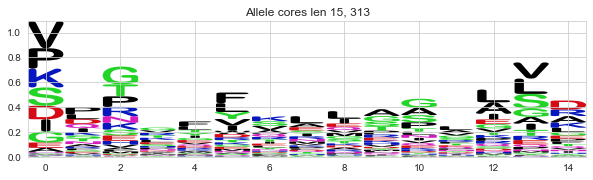

In [135]:
make_logo_for_data(cores, f"cores len {target_core_len}")

In [128]:
df.core_start.value_counts()

0    742
1    537
2     70
3     28
4      5
Name: core_start, dtype: int64

In [129]:
df.peptide_len.value_counts()

15    705
16    272
17    209
18    141
14     55
Name: peptide_len, dtype: int64

In [248]:
df

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,Gibbs_core
MDNDLAATNDHNVME,"[0.0, 0.97, 2.92, 2.92, 3.86, 3.86, 3.86, 4.8,...",2,10,9,15,NDLAATNDH,"[2.92, 2.92, 3.86, 3.86, 3.86, 4.8, 3.83, 1.88...",NaN
EFHLDGEVLSLDKLK,"[0.0, 2.85, 2.85, 3.84, 4.81, 4.81, 4.81, 4.81...",1,9,9,15,FHLDGEVLS,"[2.85, 2.85, 3.84, 4.81, 4.81, 4.81, 4.81, 2.9...",NaN
SPSIVIALAGNKADL,"[0.95, 0.95, 2.93, 2.93, 3.92, 3.92, 3.92, 3.9...",2,10,9,15,SIVIALAGN,"[2.93, 2.93, 3.92, 3.92, 3.92, 3.97, 3.97, 1.9...",VIALAGNKA
ERSLWIIFSKNLNIK,"[0.99, 2.92, 2.92, 3.9, 3.9, 3.9, 4.87, 3.88, ...",1,9,9,15,RSLWIIFSK,"[2.92, 2.92, 3.9, 3.9, 3.9, 4.87, 3.88, 1.95, ...",LWIIFSKNL
LSYRSLQPETFAVVD,"[1.97, 1.97, 3.96, 3.96, 3.96, 4.9, 4.9, 3.92,...",0,8,9,15,LSYRSLQPE,"[1.97, 1.97, 3.96, 3.96, 3.96, 4.9, 4.9, 3.92,...",YRSLQPETF
...,...,...,...,...,...,...,...,...
SKFMQEINIEEQEYQ,"[0.94, 1.9, 2.89, 4.82, 4.82, 4.82, 4.82, 4.82...",1,9,9,15,KFMQEINIE,"[1.9, 2.89, 4.82, 4.82, 4.82, 4.82, 4.82, 3.88...",FMQEINIEE
APVGIMFLVAGKIVE,"[0.0, 0.0, 2.88, 2.88, 3.86, 3.86, 3.86, 4.85,...",2,10,9,15,VGIMFLVAG,"[2.88, 2.88, 3.86, 3.86, 3.86, 4.85, 4.85, 2.9...",IMFLVAGKI
AGLIAIVMVTILLCC,"[1.9, 2.82, 3.77, 3.77, 3.77, 3.77, 3.77, 3.81...",0,8,9,15,AGLIAIVMV,"[1.9, 2.82, 3.77, 3.77, 3.77, 3.77, 3.77, 3.81...",NaN
LLIIFKNQASRPYNI,"[0.0, 0.99, 2.96, 2.96, 4.85, 4.85, 4.85, 4.85...",2,10,9,15,IIFKNQASR,"[2.96, 2.96, 4.85, 4.85, 4.85, 4.85, 3.86, 1.8...",FKNQASRPY


# Continue with old approach

# Calculate viterbi path for each input peptide

In [99]:
from tqdm import tqdm
def get_all_viterbi_paths_for_model_and_sequences_mark_core(model, peptides, edge_value="log_probability", precision=4,
                                                           start_states=None,
                                                            end_states=None):
    print(f"Model {model.name}")
    model_graph = model.graph
    print(f"Core starts at {start_states} and ends at {end_states}")
    print("Get viterbi paths for each peptide...")
    
    
    

    result_probs = list()
    result_normalized_probs = list()
    result_lens = list()
    result_paths = list()
    result_peptides = list()
    result_viterbi_probs = list()
    result_start_core = list()
    result_end_core = list()


    for i, peptide in tqdm(enumerate(peptides), total=len(peptides)):
        viterbi_prob, path = model.viterbi(peptide)
        # calulate onlu edges prob
        prob_for_path = 0 if edge_value == "log_probability" else 1
        path_nodes = [path_tuple[1] for path_tuple in path]

        path_length = len(path_nodes)
        result_paths.append(">".join([node.name for node in path_nodes]))
        
        start_state_indexes =  [i - 1  for i, state in enumerate(path_nodes) if state.name in start_states] #minus 1 because of start_state
        end_state_indexes =  [i - 1 for i, state in enumerate(path_nodes) if state.name in end_states] #minus 1 because of start_state

        start_core = start_state_indexes[0] if len(start_state_indexes) > 0 else np.nan
        end_core = end_state_indexes[-1] if len(end_state_indexes) > 0 else np.nan

        node_from = path_nodes.pop(0)
        while path_nodes:
            node_to = path_nodes.pop(0)
            data = model_graph.get_edge_data(node_from, node_to, default=None)
            log_probability = data['probability']
            # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + log_probability
            else:
                prob_for_path = prob_for_path * np.exp(log_probability)
            # print(f"edge {edge}")
            node_from = node_to
        result_lens.append(path_length - 2)
        result_probs.append(prob_for_path)
        result_normalized_probs.append(prob_for_path / path_length)
        result_viterbi_probs.append(viterbi_prob)
        result_start_core.append(start_core)
        result_end_core.append(end_core)
    # unique_paths = list(path_code_to_path.values())
    # for path in tqdm(unique_paths):
    #     prob_for_path = 0 if edge_value == "log_probability" else 1
    #     path_edges = path.copy()
    #     node_from = path_edges.pop(0)
    #     while path_edges:
    #         node_to = path_edges.pop(0)
    #         data = model_graph.get_edge_data(node_from, node_to, default=None)
    #         log_probability = data['probability']
    #         # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
    #         if edge_value == "log_probability":
    #             prob_for_path = prob_for_path + log_probability
    #         else:
    #             prob_for_path = prob_for_path * np.exp(log_probability)
    #         # print(f"edge {edge}")
    #         node_from = node_to
    #     result_paths.append(">".join([node.name for node in path]))
    #     result_lens.append(len(path) - 2)
    #     result_probs.append(prob_for_path)
    #     # normalize
    #     result_normalized_probs.append(prob_for_path / len(path))

    paths_df = pd.DataFrame(
        {"path": result_paths, "prob": result_probs, "normalized_prob": result_normalized_probs, "core_start": result_start_core, "core_end": result_end_core, "len": result_lens,
         "viterbi_probs": result_viterbi_probs}, index=peptides)
    # paths_df = paths_df.sort_values('normalized_prob', ascending=False)
    # paths_df = paths_df.reset_index(drop=True)
    return paths_df


# Check new model in a similar way!

In [100]:
core_start_state= MODELS_DESCRIPTIONS[selected_models[0]]['core_start_state']
core_end_state = MODELS_DESCRIPTIONS[selected_models[0]]['core_end_state']

In [101]:
from tqdm import tqdm
def get_all_viterbi_paths_for_model_and_sequences_mark_core(model, peptides, edge_value="log_probability", precision=4,
                                                           start_states=None,
                                                            end_states=None):
    print(f"Model {model.name}")
    model_graph = model.graph
    print(f"Core starts at {start_states} and ends at {end_states}")
    print("Get viterbi paths for each peptide...")
    
    
    

    result_probs = list()
    result_normalized_probs = list()
    result_lens = list()
    result_paths = list()
    result_peptides = list()
    result_viterbi_probs = list()
    result_start_core = list()
    result_end_core = list()


    for i, peptide in tqdm(enumerate(peptides), total=len(peptides)):
        viterbi_prob, path = model.viterbi(peptide)
        # calulate onlu edges prob
        prob_for_path = 0 if edge_value == "log_probability" else 1
        path_nodes = [path_tuple[1] for path_tuple in path]

        path_length = len(path_nodes)
        result_paths.append(">".join([node.name for node in path_nodes]))
        
        start_state_indexes =  [i - 1  for i, state in enumerate(path_nodes) if state.name in start_states] #minus 1 because of start_state
        end_state_indexes =  [i - 1 for i, state in enumerate(path_nodes) if state.name in end_states] #minus 1 because of start_state

        start_core = start_state_indexes[0] if len(start_state_indexes) > 0 else np.nan
        end_core = end_state_indexes[-1] if len(end_state_indexes) > 0 else np.nan

        node_from = path_nodes.pop(0)
        while path_nodes:
            node_to = path_nodes.pop(0)
            data = model_graph.get_edge_data(node_from, node_to, default=None)
            log_probability = data['probability']
            # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + log_probability
            else:
                prob_for_path = prob_for_path * np.exp(log_probability)
            # print(f"edge {edge}")
            node_from = node_to
        result_lens.append(path_length - 2)
        result_probs.append(prob_for_path)
        result_normalized_probs.append(prob_for_path / path_length)
        result_viterbi_probs.append(viterbi_prob)
        result_start_core.append(start_core)
        result_end_core.append(end_core)
    # unique_paths = list(path_code_to_path.values())
    # for path in tqdm(unique_paths):
    #     prob_for_path = 0 if edge_value == "log_probability" else 1
    #     path_edges = path.copy()
    #     node_from = path_edges.pop(0)
    #     while path_edges:
    #         node_to = path_edges.pop(0)
    #         data = model_graph.get_edge_data(node_from, node_to, default=None)
    #         log_probability = data['probability']
    #         # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
    #         if edge_value == "log_probability":
    #             prob_for_path = prob_for_path + log_probability
    #         else:
    #             prob_for_path = prob_for_path * np.exp(log_probability)
    #         # print(f"edge {edge}")
    #         node_from = node_to
    #     result_paths.append(">".join([node.name for node in path]))
    #     result_lens.append(len(path) - 2)
    #     result_probs.append(prob_for_path)
    #     # normalize
    #     result_normalized_probs.append(prob_for_path / len(path))

    paths_df = pd.DataFrame(
        {"path": result_paths, "prob": result_probs, "normalized_prob": result_normalized_probs, "core_start": result_start_core, "core_end": result_end_core, "len": result_lens,
         "viterbi_probs": result_viterbi_probs}, index=peptides)
    # paths_df = paths_df.sort_values('normalized_prob', ascending=False)
    # paths_df = paths_df.reset_index(drop=True)
    return paths_df


In [102]:
per_model_anchors = dict()
per_name_models = per_name_binding_model
core_start_state= MODELS_DESCRIPTIONS[selected_models[0]]['core_start_state']
core_end_state = MODELS_DESCRIPTIONS[selected_models[0]]['core_end_state']
for model_key, model in per_name_models.items():
    per_model_anchors[model_key] = dict()
    per_model_anchors[model_key]['max'] = model.states[core_end_state].name
    per_model_anchors[model_key]['min'] = model.states[core_start_state].name
    

In [103]:
per_model_anchors

{'0_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0': {'max': 's026',
  'min': 's025'},
 '1_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0': {'max': 's026',
  'min': 's025'},
 '2_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0': {'max': 's026',
  'min': 's025'},
 '3_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0': {'max': 's026',
  'min': 's025'},
 '4_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0': {'max': 's026',
  'min': 's025'}}

In [104]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [105]:
per_model_core_start = defaultdict(list)
per_model_core_end = defaultdict(list)

result_df = pd.DataFrame(index=allele_peptides)

for i, (model_key, model) in enumerate(per_name_models.items()):
    viterbi_paths = get_all_viterbi_paths_for_model_and_sequences_mark_core(model, allele_peptides,
                                                                                   start_states=per_model_anchors[model_key]['min'],
                                                                                   end_states=per_model_anchors[model_key]['max'])
    result_df[f'core_start_{i}'] = viterbi_paths['core_start'].values
    result_df[f'core_end_{i}'] = viterbi_paths['core_end'].values
    result_df[f'v_prob_{i}'] = viterbi_paths['viterbi_probs'].values
    
    
    #find anchor for each model
    

Model 0_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Core starts at s025 and ends at s026
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:01<00:00, 11463.65it/s]


Model 1_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Core starts at s025 and ends at s026
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:01<00:00, 10521.43it/s]


Model 2_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Core starts at s025 and ends at s026
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:00<00:00, 13474.82it/s]


Model 3_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Core starts at s025 and ends at s026
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:00<00:00, 12001.01it/s]


Model 4_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Core starts at s025 and ends at s026
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:00<00:00, 16341.91it/s]


In [106]:
result_df

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4
LPWNSLPAKTLSK,5,11,-36.433899,0,7,-38.300557,2,8,-42.064700,2,8,-35.705307,0,6,-39.349545
IDPIWSLAANHLS,6,12,-38.122537,1,7,-38.486473,1,7,-39.396837,3,9,-37.676468,1,7,-39.453690
DSRLVLEVAQHLG,6,12,-38.290449,1,7,-37.092241,0,6,-37.086968,3,9,-36.277509,1,8,-36.589126
FLSFPTTKTYFPH,1,7,-42.770012,1,8,-44.869600,0,6,-44.325921,0,6,-45.850577,1,8,-44.765592
AAGYDVEKNNSRI,6,12,-42.594572,1,8,-37.728252,0,6,-40.328688,3,9,-37.386060,1,9,-41.017244
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,7,13,-54.773572,2,9,-52.140510,1,7,-52.915872,4,11,-53.748754,2,9,-53.080843
AVPGKTFVSITPAEVGVL,9,15,-52.998724,4,10,-50.204575,3,9,-50.163255,6,12,-50.067367,4,10,-50.569509
VPHLRYLRLDGNYLKPPI,8,14,-52.461933,1,8,-54.117145,2,8,-53.838727,5,11,-52.352251,1,8,-53.511097
DIRRFDPIPAQYVRVYPE,7,13,-55.379731,2,9,-56.036721,1,7,-55.581909,4,10,-55.175012,2,8,-56.240885


In [343]:
result_df['len'] = result_df.index.str.len()

In [344]:
result_df[result_df['len']==15]

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4,len
IVLSSELRLSHSRTH,2,8,-46.184237,4,11,-47.084595,3,9,-46.249582,6,12,-46.518778,5,13,-48.112668,15
MDNDLAATNDHNVME,7,13,-51.834905,2,8,-50.808451,1,7,-51.214223,4,10,-51.765642,2,8,-52.039667,15
EFHLDGEVLSLDKLK,3,9,-42.866300,1,7,-46.328549,4,10,-44.727821,1,7,-46.650210,1,8,-45.757055,15
SPSIVIALAGNKADL,7,13,-40.504891,2,8,-41.875212,0,6,-42.439952,4,10,-40.557440,2,8,-40.184039,15
ERSLWIIFSKNLNIK,6,12,-46.847361,1,7,-47.213453,0,6,-47.347887,3,9,-47.063905,1,7,-47.880625,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LLIIFKNQASRPYNI,4,10,-49.378744,2,8,-47.076590,1,7,-47.573108,4,10,-46.711595,2,8,-47.620495,15
ETQYSEMFGMVLAPA,6,12,-46.075367,1,7,-45.956662,0,6,-45.715244,3,9,-44.801549,1,7,-45.906706,15
FNMVYMPASWVMRIM,5,11,-52.155026,2,8,-53.815348,1,7,-53.146985,2,8,-52.295265,2,11,-53.376243,15
IFLSKDLQADIKGRD,7,13,-45.654156,2,8,-48.842987,3,9,-48.437682,3,9,-48.424849,4,10,-47.178443,15


In [345]:
peptide = 'IVLSSELRLSHSRTH'

model = per_name_models[list(per_name_models.keys())[0]]

In [346]:
prob, path = model.viterbi(peptide)

In [347]:
[item[0] for item in path]

[29, 27, 27, 25, 3, 6, 12, 16, 24, 26, 28, 28, 28, 28, 28, 28, 30]

In [348]:
peptide

'IVLSSELRLSHSRTH'

In [349]:
prob, path = model.maximum_a_posteriori([i for i in peptide])


In [350]:
[item[0] for item in path]

[27, 27, 27, 3, 6, 12, 16, 24, 26, 28, 28, 28, 28, 28, 28]

In [351]:
result_df

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4,len
LPWNSLPAKTLSK,5,11,-36.433899,0,7,-38.300557,2,8,-42.064700,2,8,-35.705307,0,6,-39.349545,13
IDPIWSLAANHLS,6,12,-38.122537,1,7,-38.486473,1,7,-39.396837,3,9,-37.676468,1,7,-39.453690,13
DSRLVLEVAQHLG,6,12,-38.290449,1,7,-37.092241,0,6,-37.086968,3,9,-36.277509,1,8,-36.589126,13
FLSFPTTKTYFPH,1,7,-42.770012,1,8,-44.869600,0,6,-44.325921,0,6,-45.850577,1,8,-44.765592,13
AAGYDVEKNNSRI,6,12,-42.594572,1,8,-37.728252,0,6,-40.328688,3,9,-37.386060,1,9,-41.017244,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,7,13,-54.773572,2,9,-52.140510,1,7,-52.915872,4,11,-53.748754,2,9,-53.080843,18
AVPGKTFVSITPAEVGVL,9,15,-52.998724,4,10,-50.204575,3,9,-50.163255,6,12,-50.067367,4,10,-50.569509,18
VPHLRYLRLDGNYLKPPI,8,14,-52.461933,1,8,-54.117145,2,8,-53.838727,5,11,-52.352251,1,8,-53.511097,18
DIRRFDPIPAQYVRVYPE,7,13,-55.379731,2,9,-56.036721,1,7,-55.581909,4,10,-55.175012,2,8,-56.240885,18


In [352]:
result_df['core_length'] = result_df['core_end_1'] + 1- result_df['core_start_1']

In [353]:
result_df['core_length'].value_counts()

7     7711
8     3687
9      587
10      16
Name: core_length, dtype: int64

In [354]:
result_df[result_df['len'] == 15]['core_length'].value_counts()

7     4606
8     1966
9      302
10      12
Name: core_length, dtype: int64

In [362]:
df = result_df[result_df['len'] == 15]
df = df[df['core_length'] == 8]

NameError: name 'result_df' is not defined

In [370]:
peptides = df.index.values 
core_starts = df['core_start_1'].values
core_ends = df['core_end_1'].values


In [371]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

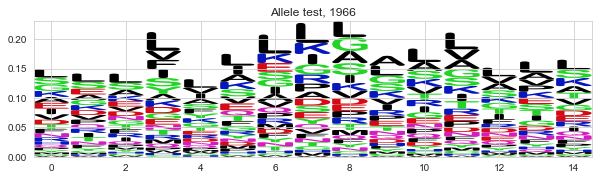

In [372]:
make_logo_for_data(peptides, "test")

In [373]:
cores = [peptide[core_starts[i]:core_ends[i] + 1] for i,peptide in enumerate(peptides)]
         

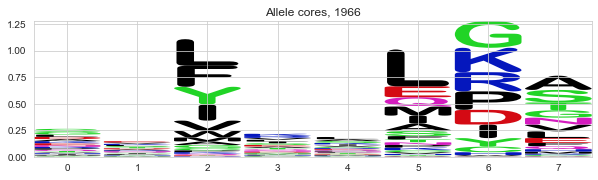

In [374]:
make_logo_for_data(cores, "cores")

In [368]:
df['core_start_0'].value_counts()

6    1113
7    1098
5     659
4     476
8     454
3     426
2     226
1     154
Name: core_start_0, dtype: int64

## Forward-Backward estimate to find core

In [325]:
per_model_core_start = defaultdict(list)
per_model_core_end = defaultdict(list)

result_df = pd.DataFrame(index=allele_peptides)

for i, (model_key, model) in enumerate(per_name_models.items()):
    core_starts = list()
    core_ends = list()
    for peptide in allele_peptides:
        fb_result = model.forward_backward(peptide)[1]
        arg_min = fb_result.argmax(axis=0)
        min_position = arg_min[core_start_state]
        max_position = arg_min[core_end_state]
        # assert min_position < max_position
        core_starts.append(min_position)
        core_ends.append(max_position)
    
    result_df[f'core_start_{i}'] = core_starts
    result_df[f'core_end_{i}'] = core_ends


In [336]:
result_df['len'] = result_df.index.str.len()
result_df['core_length'] = result_df['core_end_1'] + 1 - result_df['core_start_1']

In [327]:
result_df['core_length'].value_counts()

7     11729
8       201
9        11
11       10
6         9
4         9
10        8
5         7
12        5
3         4
2         4
13        3
0         1
Name: core_length, dtype: int64

In [328]:
result_df[result_df['len'] == 15]['core_length'].value_counts()

7     6732
8      107
9        9
4        8
11       8
10       6
12       4
6        4
5        4
3        2
2        2
Name: core_length, dtype: int64

In [329]:
result_df[result_df['len'] == 15]

,core_start_0,core_end_0,core_start_1,core_end_1,core_start_2,core_end_2,core_start_3,core_end_3,core_start_4,core_end_4,len,core_length
IVLSSELRLSHSRTH,2,8,4,11,3,9,6,12,5,13,15,7
MDNDLAATNDHNVME,7,13,2,8,1,7,4,10,2,8,15,7
EFHLDGEVLSLDKLK,3,9,1,7,4,10,1,7,1,8,15,7
SPSIVIALAGNKADL,7,13,2,8,0,7,4,10,2,8,15,7
ERSLWIIFSKNLNIK,6,12,1,7,0,6,3,9,1,7,15,7
...,...,...,...,...,...,...,...,...,...,...,...,...
LLIIFKNQASRPYNI,4,10,2,8,1,7,4,10,2,8,15,7
ETQYSEMFGMVLAPA,6,12,1,7,0,6,3,9,1,7,15,7
FNMVYMPASWVMRIM,5,11,2,8,1,7,2,8,2,11,15,7
IFLSKDLQADIKGRD,7,13,2,8,3,9,3,9,4,10,15,7


In [330]:
df = result_df[result_df['len'] == 15]
df = df[df['core_length'] == 7]

In [331]:
peptides = df.index.values 
core_starts = df['core_start_0'].values
core_ends = df['core_end_0'].values


In [332]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

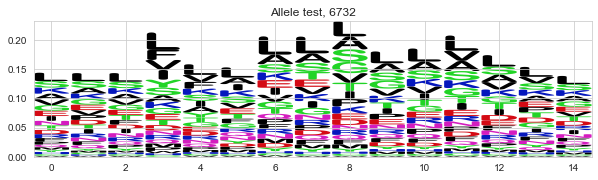

In [333]:
make_logo_for_data(peptides, "test")

In [334]:
cores = [peptide[core_starts[i]+1:core_ends[i]] for i,peptide in enumerate(peptides)]
         

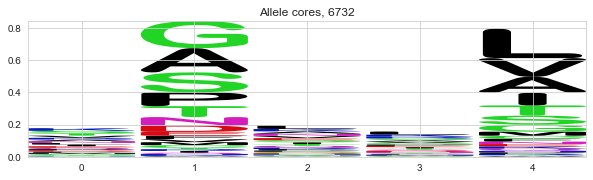

In [335]:
make_logo_for_data(cores, "cores")

In [100]:
df

,core_start_0,core_end_0,core_start_1,core_end_1,core_start_2,core_end_2,core_start_3,core_end_3,core_start_4,core_end_4,len,core_length
IVLSSELRLSHSRTH,1,13,1,13,1,13,1,13,1,13,15,13
MDNDLAATNDHNVME,1,13,1,13,1,13,1,13,1,13,15,13
SPSIVIALAGNKADL,1,13,1,13,1,13,1,13,1,13,15,13
ERSLWIIFSKNLNIK,1,13,1,12,1,12,1,12,1,12,15,13
LSYRSLQPETFAVVD,1,13,1,12,1,12,1,12,0,13,15,13
...,...,...,...,...,...,...,...,...,...,...,...,...
FDTGLMNDTGPILRL,1,13,1,13,1,13,1,13,1,13,15,13
IMNRWTLQMGFPVIT,1,13,1,13,1,13,1,13,1,13,15,13
APVGIMFLVAGKIVE,1,13,1,13,1,13,1,13,1,13,15,13
AGLIAIVMVTILLCC,1,13,1,13,1,13,1,13,1,13,15,13


## Calculate viterbi paths for train data (Try to find anchors)

In [101]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [102]:
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences
allele_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(model, allele_peptides)


Model 4_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:00<00:00, 19774.64it/s]


Select unique paths...
	Unique paths: 2225


100%|██████████| 2225/2225 [00:00<00:00, 37955.57it/s]


In [103]:
allele_bw_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts
0,grouped_model-start>s027>s025>s000>s006>s007>s...,-6.338333,-0.396146,14,-41.321140,160
1,grouped_model-start>s027>s025>s001>s000>s006>s...,-6.821602,-0.401271,15,-48.740790,174
2,grouped_model-start>s027>s025>s001>s004>s000>s...,-7.267903,-0.403772,16,-47.953576,41
3,grouped_model-start>s027>s025>s004>s000>s006>s...,-6.921293,-0.407135,15,-47.900938,144
4,grouped_model-start>s027>s025>s000>s006>s007>s...,-6.547243,-0.409203,14,-40.803551,98
...,...,...,...,...,...,...
2220,grouped_model-start>s025>s002>s009>s014>s015>s...,-17.089083,-1.005240,15,-55.188543,1
2221,grouped_model-start>s027>s025>s001>s004>s000>s...,-15.316085,-1.021072,13,-45.592282,1
2222,grouped_model-start>s025>s000>s005>s012>s016>s...,-15.373904,-1.024927,13,-47.112920,1
2223,grouped_model-start>s027>s027>s025>s001>s004>s...,-17.423946,-1.024938,15,-59.044016,1


In [104]:
state_names = [f"s{i:03d}".format(i) for i in range(len(model.states) - 2)] # minus start minus end

# allele_bw_paths_df.loc[:,state_names] = 0

per_state_counts = dict()

In [105]:
for state_name in state_names:
    per_state_counts[state_name] =  allele_bw_paths_df[allele_bw_paths_df['path'].str.contains(state_name)]['peptide_cnts'].sum()


In [106]:
per_state_counts

{'s000': 7849,
 's001': 4522,
 's002': 2685,
 's003': 1545,
 's004': 3529,
 's005': 109,
 's006': 10080,
 's007': 10212,
 's008': 586,
 's009': 1766,
 's010': 3671,
 's011': 8268,
 's012': 187,
 's013': 11703,
 's014': 313,
 's015': 11508,
 's016': 11389,
 's017': 342,
 's018': 30,
 's019': 4817,
 's020': 1161,
 's021': 8849,
 's022': 7537,
 's023': 306,
 's024': 9942,
 's025': 12001,
 's026': 12001,
 's027': 10239,
 's028': 11996}

In [107]:
import seaborn as sns

In [108]:
df = pd.DataFrame.from_dict(per_state_counts, orient='index', columns=['cnt'])

# sns.barplot(x=list(per_state_counts.keys()), y=list(per_state_counts.values()))

<AxesSubplot:>

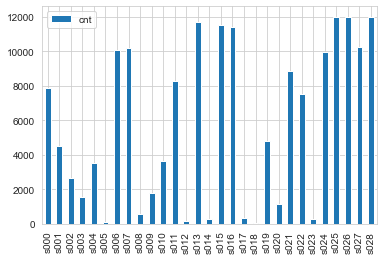

In [109]:
df.plot(kind='bar')

In [110]:
df.sort_values(by='cnt', ascending=False)

,cnt
s026,12001
s025,12001
s028,11996
s013,11703
s015,11508
s016,11389
s027,10239
s007,10212
s006,10080
s024,9942


In [88]:
model.dense_transition_matrix()

array([[0.        , 0.18783749, 0.24838837, ..., 0.        , 0.        ,
        0.        ],
       [0.02338106, 0.        , 0.08356533, ..., 0.        , 0.        ,
        0.        ],
       [0.10202855, 0.22541672, 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.70792018],
       [0.24782062, 0.12390521, 0.03135931, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])